## 1. Imports

In [77]:
import spikeinterface.full as si
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import mne

## 2. Load

In [ ]:
# Load the downsampled recording
ds_data = si.load(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\down_sampled\1000_Hz")
display(ds_data) 

# Load the beh. recording
session_dir = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750"
beh = pd.read_csv(session_dir + r"\share\trials.csv")
#display(beh)


BinaryFolderRecording: 383 channels - 1000.0Hz - 1 segments - 2,989,092 samples 
                       2,989.09s (49.82 minutes) - float32 dtype - 4.26 GiB

## 3. Settings

In [89]:


beh["tone_np_s"] = (beh["tone"] - beh["press"]) + beh["press_np_s"]
beh

outcome = "early"
trial_type = "long"

alignment = "Press"


l_C = beh [(beh[outcome]== 1) & (beh[trial_type]==1)]
print(f"{trial_type} AND {outcome} trials: {len(l_C)}")
print(f"Total trials: {len(beh)}")
print(f"{outcome} trials: {(beh[outcome] == 1).sum()}")
print(f"{trial_type}: {(beh[trial_type] == 1).sum()}")
print(f"{trial_type} AND {outcome} trials: {len(l_C)}")
#l_C

long AND early trials: 62
Total trials: 203
early trials: 83
long: 126
long AND early trials: 62


In [93]:
def highlight_intersection(row):
    if " + " in row["Measure"]:
        return ["background-color: #d5f5e3; font-weight: bold"] * len(row)
    return [""] * len(row)

styled_summary = (
    summary.style
    .apply(highlight_intersection, axis=1)
    .format({"Percentage": "{:.1f}%"})
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#34495e"),
                ("color", "white"),
                ("font-weight", "bold")
            ]
        }
    ])
)

display(styled_summary)

,Measure,Count,Percentage
0,Total trials,203,100.0%
1,Early trials,83,40.9%
2,Long trials,126,62.1%
3,Long + early trials,62,30.5%


# PSD

## Entire recording

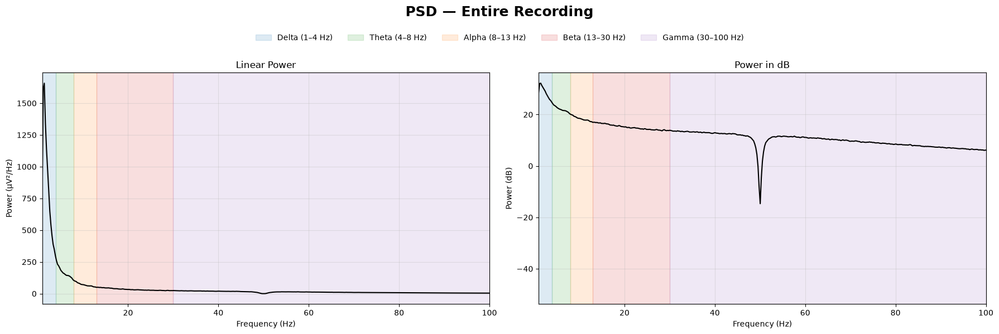

In [13]:
import mne
import numpy as np
import matplotlib.pyplot as plt


data = ds_data.get_traces(return_in_uV=True).T #get all the voltage data for all channels out of the recording to micro volts
                                               #spike interface returns (n_s , n_ch) so we need to transpose it to get the MNE shape required
fs = ds_data.get_sampling_frequency()  # 1000 Hz

#Build the mne meta data with ch names converting to strings, fs and type here stereo eeg best for depth (neuropixels)
info = mne.create_info(ch_names=[str(ch) for ch in ds_data.channel_ids], sfreq=fs, ch_types="seeg") 

#combine the actual data with meta data in raw so mne functions will operate on this
raw = mne.io.RawArray(data, info, verbose=False)

# Compute PSD real window stays 4s (4000 samples), zero-padded to 2^12 = 4096 
n_per_seg = int(fs * 4)      # 4000 samples — this sets your TRUE frequency resolution
n_fft = 2 ** 12               # 4096 — FFT length; MNE zero-pads each segment from 4000 -> 4096

spectrum = raw.compute_psd(method="welch", n_fft=n_fft, n_per_seg=n_per_seg, verbose=False) #compute psd for each channel for the entire recording with 4 seconds window with default overlap and average this time windows for each channel
power, f = spectrum.get_data(return_freqs=True) #extract the power (n_ch , n_f) and f the shared freq axis

# Average across channels
grand_avg_psd = power.mean(axis=0) 
grand_avg_psd_db = 10 * np.log10(grand_avg_psd)

#Saves copies of these three results under ent_-prefixed names ("entire recording")
# so they persist safely for later comparison plots without risk of being overwritten 
# by a different cell that reuses the generic names f/grand_avg_psd/grand_avg_psd_db
ent_f, ent_psd, ent_psd_db = f, grand_avg_psd, grand_avg_psd_db


# Plot
bands = {
    'Delta (1–4 Hz)':  (1, 4, 'tab:blue'),
    'Theta (4–8 Hz)':  (4, 8, 'tab:green'),
    'Alpha (8–13 Hz)': (8, 13, 'tab:orange'),
    'Beta (13–30 Hz)': (13, 30, 'tab:red'),
    'Gamma (30–100 Hz)': (30, 100, 'tab:purple'),
}

fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))

ax[0].plot(f, grand_avg_psd, color="black", linewidth=1.5)
ax[0].set_ylabel("Power (µV²/Hz)")
ax[0].set_title("Linear Power")

ax[1].plot(f, grand_avg_psd_db, color="black", linewidth=1.5)
ax[1].set_ylabel("Power (dB)")
ax[1].set_title("Power in dB")

band_patches = []
for name, (fmin, fmax, color) in bands.items():
    ax[0].axvspan(fmin, fmax, color=color, alpha=0.15)
    patch = ax[1].axvspan(fmin, fmax, color=color, alpha=0.15)
    band_patches.append(patch)

for a in ax:
    a.set_xlim(1, 100)
    a.set_xlabel("Frequency (Hz)")
    a.grid(alpha=0.3)

fig.suptitle("PSD — Entire Recording", fontsize=18, fontweight="bold", y=1.08)

fig.legend(handles=band_patches, labels=list(bands.keys()), loc="upper center", bbox_to_anchor=(0.5, 1.01), ncol=len(bands), frameon=False, fontsize=10)

#plt.savefig(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260513_r0000136_wt_1729\amir_data\entire_vs_event\PSD_entire_recording_zeropad4096.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

##  Press to Tone 

In [132]:
press_values = l_C['press_np_s']
print(press_values)
press_idx = np.round(press_values.values * fs).astype(int) #convert to number of samples
print(press_idx)

0        22.257466
12      232.237039
22      335.996843
24      357.506811
26      389.616747
27      411.796685
31      454.056612
32      476.566551
33      490.486521
34      504.506491
40      577.646339
42      603.236275
45      635.366197
53      711.465984
56      738.795910
58      768.765839
61      810.705760
67      891.825523
70     1007.385249
75     1081.995009
82     1175.334750
86     1224.424597
92     1284.994395
94     1304.284337
98     1368.284135
100    1393.844062
102    1417.103962
106    1465.863805
108    1486.683734
116    1557.063496
118    1592.873386
120    1613.243293
127    1698.043016
129    1724.152935
130    1743.212867
131    1781.142761
135    1858.002502
138    1904.422358
150    2052.371846
152    2089.731716
154    2113.481653
156    2144.351523
158    2175.321447
160    2206.381331
163    2240.261225
165    2275.921091
169    2368.710793
175    2479.100406
177    2492.650374
178    2505.650321
181    2535.050202
185    2596.220000
187    2620.

(55, 383, 1000)


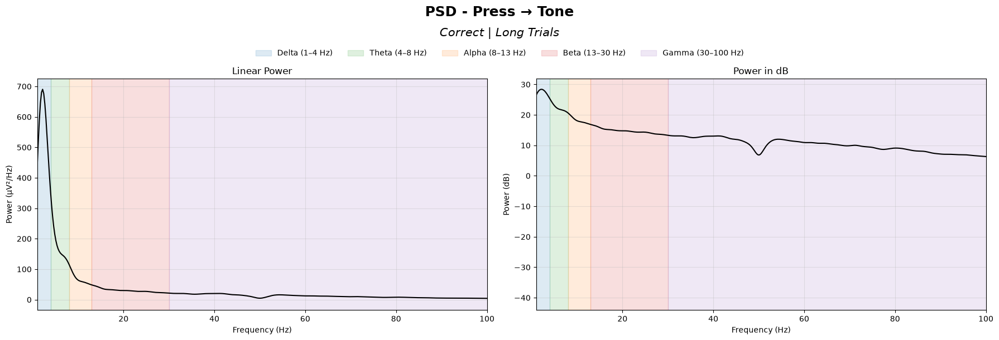

In [133]:
t_diff = 1  # seconds between press and tone
n_segment_full = round(fs * t_diff)  #Converts that 1-second duration into samples by multiplying by the sampling rate = 1000 samples

welch_s = 0.5
n_per_seg_full = round(fs * welch_s)  # 500 samples


# Get channel ids and count how many we have
all_channel_ids = ds_data.channel_ids
n_channels = len(all_channel_ids)

#Creates an empty array to hold  (number of trials, number of channels, 1000 samples)
final_full = np.zeros((len(press_idx), n_channels, n_segment_full))
for i, idx in enumerate(press_idx):
    trace = ds_data.get_traces(start_frame=idx, end_frame=idx + n_segment_full, return_in_uV=True)
    final_full[i] = trace.T

print(final_full.shape)  # (n_trials, n_channels, samples)

#Build the mne meta data with ch names converting to strings, fs and type here stereo eeg best for depth (neuropixels)
info_full = mne.create_info(ch_names=[str(ch) for ch in all_channel_ids], sfreq=fs, ch_types="seeg")
tone_full_epochs = mne.EpochsArray(final_full, info_full, verbose=False)

# Welch: 0.5 s segments within each 1 s epoch, zero-padded to 4096 — comparable to entire-recording PSD
n_fft_full = 2 ** 12

#compute psd for each channel for the entire recording with 4 seconds window with default overlap and average this time windows for each channel
spectrum_full = tone_full_epochs.compute_psd(method="welch", n_fft=n_fft_full, n_per_seg=n_per_seg_full, verbose=False)

trial_psds_full = spectrum_full.get_data()  # extract the actual power values (n_trials, n_channels, n_freqs)

tone_full_f = spectrum_full.freqs # shared freq axis

#Average across all trials which was not needed in the whole recording 
mean_psd_per_channel_full = trial_psds_full.mean(axis=0)

#average across channels
tone_full_psd = mean_psd_per_channel_full.mean(axis=0)

#convert to dB
tone_full_psd_db = 10 * np.log10(tone_full_psd)

# Plot
bands = {
    'Delta (1–4 Hz)': (1, 4, 'tab:blue'),
    'Theta (4–8 Hz)': (4, 8, 'tab:green'),
    'Alpha (8–13 Hz)': (8, 13, 'tab:orange'),
    'Beta (13–30 Hz)': (13, 30, 'tab:red'),
    'Gamma (30–100 Hz)': (30, 100, 'tab:purple'),
}

fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))
ax[0].plot(tone_full_f, tone_full_psd, color="black", linewidth=1.5)
ax[0].set_ylabel("Power (µV²/Hz)")
ax[0].set_title("Linear Power")

ax[1].plot(tone_full_f, tone_full_psd_db, color="black", linewidth=1.5)
ax[1].set_ylabel("Power (dB)")
ax[1].set_title("Power in dB")

band_patches = []
for name, (fmin, fmax, color) in bands.items():
    ax[0].axvspan(fmin, fmax, color=color, alpha=0.15)
    patch = ax[1].axvspan(fmin, fmax, color=color, alpha=0.15)
    band_patches.append(patch)

for a in ax:
    a.set_xlim(1, 100)
    a.set_xlabel("Frequency (Hz)")
    a.grid(alpha=0.3)

fig.suptitle("PSD - Press → Tone", fontsize=18, fontweight="bold", y=1.1)
fig.text(0.5, 1.0, "Correct | Long Trials", ha="center", fontsize=15, style="italic")
fig.legend( handles=band_patches,labels=list(bands.keys()),loc="upper center",bbox_to_anchor=(0.5, 0.98),ncol=len(bands),frameon=False,fontsize=10,)

plt.tight_layout()
#plt.savefig(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260513_r0000136_wt_1729\amir_data\entire_vs_event\PSD_Press_to_Tone_correct_long_zeropad4096.png",dpi=300,bbox_inches="tight",)
plt.show()

In [134]:
print("n_segment_full =", n_segment_full)
print("tone_full_f shape =", tone_full_f.shape)
print("tone_full_psd shape =", tone_full_psd.shape)
print("tone_full_psd_db shape =", tone_full_psd_db.shape)

n_segment_full = 1000
tone_full_f shape = (2049,)
tone_full_psd shape = (2049,)
tone_full_psd_db shape = (2049,)


## Press + 100 ms to Tone - 100 ms 

(55, 383, 800)


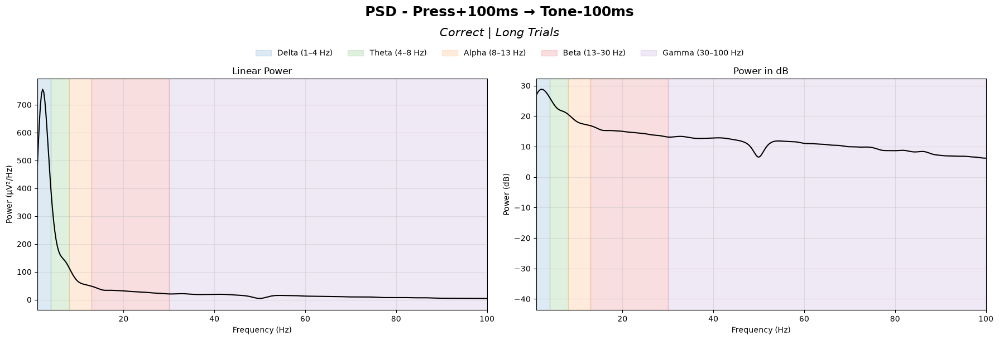

In [135]:
t_diff = 1  # seconds between press and tone — full epoch length
n_segment_full = round(fs * t_diff)  # Converts that 1-second duration into samples = 1000 samples

pad_ms = 0.1  # 100 ms trimmed from each side (press + 100ms, tone - 100ms)
n_pad = round(fs * pad_ms)  # 100 samples


n_segment_trim = n_segment_full- 2 * n_pad  # 800 samples — trimmed epoch length

welch_s_trim = 0.5
n_per_seg_trim = round(fs * welch_s_trim)  # 500 samples


# Creates an empty array to hold (number of trials, number of channels, 800 samples)
final_trim = np.zeros((len(press_idx), n_channels, n_segment_trim))
for i, idx in enumerate(press_idx):
    start = idx + n_pad               # press + 100ms
    end = idx + n_segment_full - n_pad  # tone - 100ms
    trace = ds_data.get_traces(start_frame=start, end_frame=end, return_in_uV=True)
    final_trim[i] = trace.T

print(final_trim.shape)  # (n_trials, n_channels, samples)

# Build the mne meta data with ch names converting to strings, fs and type here stereo eeg best for depth (neuropixels)
info_trim = mne.create_info(ch_names=[str(ch) for ch in all_channel_ids], sfreq=fs, ch_types="seeg")
segment_trim= mne.EpochsArray(final_trim, info_trim, verbose=False)

# Welch: 0.5 s segments within each trimmed epoch, zero-padded to 4096 — comparable to entire-recording PSD
n_fft_trim = 2 ** 12

spectrum_trim = segment_trim.compute_psd(method="welch", n_fft=n_fft_trim, n_per_seg=n_per_seg_trim,n_overlap=200, verbose=False)  # starts at 0 and 300 ms -> covers all 800 samples

trial_psds_trim = spectrum_trim.get_data()  # (n_trials, n_channels, n_freqs)
tone_trim_f = spectrum_trim.freqs

mean_psd_per_channel_trim = trial_psds_trim.mean(axis=0)
tone_trim_psd = mean_psd_per_channel_trim.mean(axis=0)
tone_trim_psd_db = 10 * np.log10(tone_trim_psd)

# Plot
bands = {
    'Delta (1–4 Hz)': (1, 4, 'tab:blue'),
    'Theta (4–8 Hz)': (4, 8, 'tab:green'),
    'Alpha (8–13 Hz)': (8, 13, 'tab:orange'),
    'Beta (13–30 Hz)': (13, 30, 'tab:red'),
    'Gamma (30–100 Hz)': (30, 100, 'tab:purple'),
}

fig, ax = plt.subplots(1, 2, figsize=(18, 5.5))
ax[0].plot(tone_trim_f, tone_trim_psd, color="black", linewidth=1.5)
ax[0].set_ylabel("Power (µV²/Hz)")
ax[0].set_title("Linear Power")

ax[1].plot(tone_trim_f, tone_trim_psd_db, color="black", linewidth=1.5)
ax[1].set_ylabel("Power (dB)")
ax[1].set_title("Power in dB")

band_patches = []
for name, (fmin, fmax, color) in bands.items():
    ax[0].axvspan(fmin, fmax, color=color, alpha=0.15)
    patch = ax[1].axvspan(fmin, fmax, color=color, alpha=0.15)
    band_patches.append(patch)

for a in ax:
    a.set_xlim(1, 100)
    a.set_xlabel("Frequency (Hz)")
    a.grid(alpha=0.3)

fig.suptitle("PSD - Press+100ms → Tone-100ms", fontsize=18, fontweight="bold", y=1.1)
fig.text(0.5, 1.0, "Correct | Long Trials", ha="center", fontsize=15, style="italic")
fig.legend(
    handles=band_patches,
    labels=list(bands.keys()),
    loc="upper center",
    bbox_to_anchor=(0.5, 0.98),
    ncol=len(bands),
    frameon=False,
    fontsize=10,
)

plt.tight_layout()
#plt.savefig(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260513_r0000136_wt_1729\amir_data\entire_vs_event\PSD_Press100ms_to_Tone100ms_correct_long_zeropad4096.png", dpi=300, bbox_inches="tight")
plt.show()


## Press to Release

In [136]:
#Duration
print(type(l_C))
print((l_C["release_np_s"] - l_C["press_np_s"]).head(10))

<class 'pandas.core.frame.DataFrame'>
0     1.369998
12    1.109999
22    1.329999
24    1.349997
26    1.199997
27    1.279999
31    1.229997
32    1.229997
33    1.259997
34    1.519996
dtype: float64


In [137]:

pr_press_times = l_C['press_np_s'].values
pr_release_times = l_C['release_np_s'].values

In [142]:
from scipy.signal import welch
# PRESS → RELEASE HELPER FUNCTIONS

def compute_release_condition_psd(press_times, release_times, fs, win_len, n_fft, n_pad=0):
    """
    Computes a trial-averaged PSD for a variable-duration, event-locked condition
    (e.g. Press->Release), guaranteeing every trial is fully covered by windows.
    Set n_pad=0 for the untrimmed condition, or n_pad=100-sample-equivalent for the trimmed one.
    """
    trial_psds = []                                            # collects one PSD per trial
    skipped = 0                                                 # counts trials too short to use
    freqs = None                                                # shared freq axis, filled on first valid trial

    for press, release in zip(press_times, release_times):     # loop over each trial's press/release timestamps
        start_idx = int(round(press * fs)) + n_pad             # convert press time to sample index, add trim pad
        end_idx = int(round(release * fs)) - n_pad              # convert release time to sample index, subtract trim pad
        segment = ds_data.get_traces(start_frame=start_idx, end_frame=end_idx, return_in_uV=True)  # extract this trial's raw data

        trial_psd, f = trial_psd_full_coverage(segment, fs, win_len=win_len, n_fft=n_fft)  # full-coverage Welch PSD for this trial
        if trial_psd is None:                                    # trial shorter than one window
            skipped += 1                                         # count it as skipped
            continue                                              # move to next trial

        freqs = f                                                 # freq axis is identical across trials, keep latest
        trial_psds.append(trial_psd)                             # store this trial's per-channel PSD

    trial_psds = np.array(trial_psds)                            # stack into (n_trials_used, n_channels, n_freqs)
    mean_psd_per_channel = trial_psds.mean(axis=0)                # average across trials -> (n_channels, n_freqs)
    grand_avg_psd = mean_psd_per_channel.mean(axis=0)             # average across channels -> (n_freqs,)
    grand_avg_psd_db = 10 * np.log10(grand_avg_psd)               # convert to dB

    n_used = len(trial_psds)                                     # how many trials contributed
    return freqs, grand_avg_psd, grand_avg_psd_db, n_used, skipped  # return everything needed downstream

In [148]:
from scipy.signal import welch

def get_window_starts(n_samples, win_len, target_overlap_frac=0.5):
    if n_samples < win_len:
        return None
    if n_samples == win_len:
        return [0]
    step = max(1, round(win_len * (1 - target_overlap_frac)))
    starts = list(range(0, n_samples - win_len + 1, step))
    if starts[-1] != n_samples - win_len:
        starts.append(n_samples - win_len)
    return starts

def trial_psd_full_coverage(segment, fs, win_len, n_fft, target_overlap_frac=0.5, window="hann"):
    n_samples, n_channels = segment.shape
    starts = get_window_starts(n_samples, win_len, target_overlap_frac)
    if starts is None:
        return None, None

    window_psds = []
    freqs = None
    for start in starts:
        chunk = segment[start:start + win_len, :]
        f, pxx = welch(chunk, fs=fs, window=window, nperseg=win_len,
                       noverlap=0, nfft=n_fft, axis=0, detrend=False)
        window_psds.append(pxx.T)
        freqs = f

    trial_psd = np.array(window_psds).mean(axis=0)
    return trial_psd, freqs

Trials used: 55 / 55 (skipped 0)


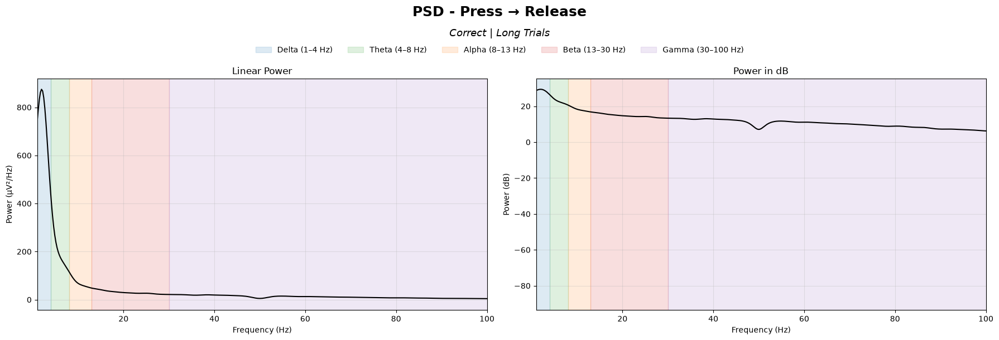

In [149]:
pr_fs = ds_data.get_sampling_frequency()
pr_n_trials = len(l_C)
pr_n_per_seg = 500
pr_n_fft = 2 ** 12

pr_trial_psds = []
pr_skipped = 0

for pr_press, pr_release in zip(pr_press_times, pr_release_times):
    pr_start_idx = int(round(pr_press * pr_fs))
    pr_end_idx = int(round(pr_release * pr_fs))
    pr_segment = ds_data.get_traces(start_frame=pr_start_idx, end_frame=pr_end_idx, return_in_uV=True)

    trial_psd, pr_freqs = trial_psd_full_coverage(pr_segment, pr_fs, win_len=pr_n_per_seg, n_fft=pr_n_fft)
    if trial_psd is None:
        pr_skipped += 1
        continue
    pr_trial_psds.append(trial_psd)

print(f"Trials used: {len(pr_trial_psds)} / {pr_n_trials} (skipped {pr_skipped})")

pr_trial_psds = np.array(pr_trial_psds)
pr_mean_psd_per_channel = pr_trial_psds.mean(axis=0)
pr_grand_avg_psd = pr_mean_psd_per_channel.mean(axis=0)
pr_grand_avg_psd_db = 10 * np.log10(pr_grand_avg_psd)

rel_full_f = pr_freqs
rel_full_psd = pr_grand_avg_psd
rel_full_psd_db = pr_grand_avg_psd_db

# Plot
pr_bands = {
    'Delta (1–4 Hz)': (1, 4, 'tab:blue'),
    'Theta (4–8 Hz)': (4, 8, 'tab:green'),
    'Alpha (8–13 Hz)': (8, 13, 'tab:orange'),
    'Beta (13–30 Hz)': (13, 30, 'tab:red'),
    'Gamma (30–100 Hz)': (30, 100, 'tab:purple'),
}

pr_fig, pr_ax = plt.subplots(1, 2, figsize=(18, 5.5))
pr_ax[0].plot(rel_full_f, rel_full_psd, color="black", linewidth=1.5)
pr_ax[0].set_ylabel("Power (µV²/Hz)")
pr_ax[0].set_title("Linear Power")
pr_ax[1].plot(rel_full_f, rel_full_psd_db, color="black", linewidth=1.5)
pr_ax[1].set_ylabel("Power (dB)")
pr_ax[1].set_title("Power in dB")

pr_band_patches = []
for pr_name, (pr_fmin, pr_fmax, pr_color) in pr_bands.items():
    pr_ax[0].axvspan(pr_fmin, pr_fmax, color=pr_color, alpha=0.15)
    pr_patch = pr_ax[1].axvspan(pr_fmin, pr_fmax, color=pr_color, alpha=0.15)
    pr_band_patches.append(pr_patch)

for pr_a in pr_ax:
    pr_a.set_xlim(1, 100)
    pr_a.set_xlabel("Frequency (Hz)")
    pr_a.grid(alpha=0.3)

pr_fig.suptitle("PSD - Press → Release", fontsize=18, fontweight="bold", y=1.1)
pr_fig.text(0.5, 1.0, "Correct | Long Trials", ha="center", fontsize=13, style="italic")

pr_fig.legend(
    handles=pr_band_patches,
    labels=list(pr_bands.keys()),
    loc="upper center",
    bbox_to_anchor=(0.5, 0.99),
    ncol=len(pr_bands),
    frameon=False,
    fontsize=10
)

plt.tight_layout()
#plt.savefig(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260513_r0000136_wt_1729\amir_data\entire_vs_event\PSD_Press_to__correct_long_zeropad4096.png",dpi=300,bbox_inches="tight",)

plt.show()

## Press + 100 ms to Release - 100 ms

Trials used: 55 / 55 (skipped 0)


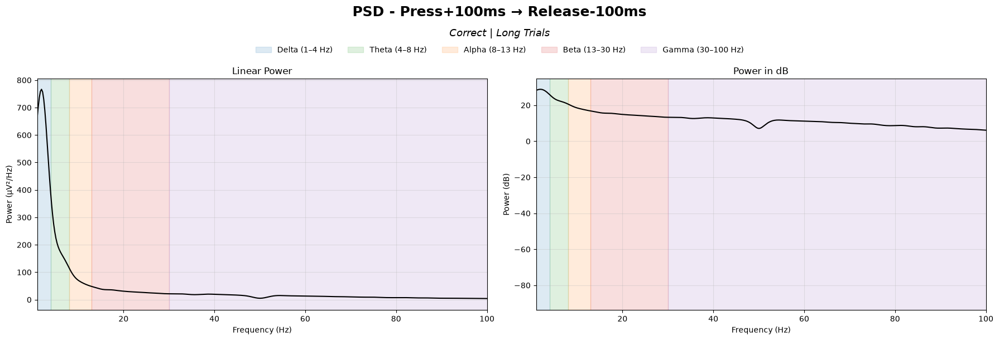

In [150]:
pr_pad_ms = 0.1
pr_n_pad = round(pr_fs * pr_pad_ms)

pr_trial_psds_trim = []
pr_skipped_trim = 0

for pr_press, pr_release in zip(pr_press_times, pr_release_times):
    pr_start_idx = int(round(pr_press * pr_fs)) + pr_n_pad
    pr_end_idx = int(round(pr_release * pr_fs)) - pr_n_pad
    pr_segment = ds_data.get_traces(start_frame=pr_start_idx, end_frame=pr_end_idx, return_in_uV=True)

    trial_psd, pr_freqs_trim = trial_psd_full_coverage(pr_segment, pr_fs, win_len=pr_n_per_seg, n_fft=pr_n_fft)
    if trial_psd is None:
        pr_skipped_trim += 1
        continue
    pr_trial_psds_trim.append(trial_psd)

print(f"Trials used: {len(pr_trial_psds_trim)} / {pr_n_trials} (skipped {pr_skipped_trim})")

pr_trial_psds_trim = np.array(pr_trial_psds_trim)
pr_mean_psd_per_channel_trim = pr_trial_psds_trim.mean(axis=0)
pr_grand_avg_psd_trim = pr_mean_psd_per_channel_trim.mean(axis=0)
pr_grand_avg_psd_db_trim = 10 * np.log10(pr_grand_avg_psd_trim)

rel_trim_f = pr_freqs_trim
rel_trim_psd = pr_grand_avg_psd_trim
rel_trim_psd_db = pr_grand_avg_psd_db_trim

# Plot
pr_bands = {
    'Delta (1–4 Hz)': (1, 4, 'tab:blue'),
    'Theta (4–8 Hz)': (4, 8, 'tab:green'),
    'Alpha (8–13 Hz)': (8, 13, 'tab:orange'),
    'Beta (13–30 Hz)': (13, 30, 'tab:red'),
    'Gamma (30–100 Hz)': (30, 100, 'tab:purple'),
}

pr_fig, pr_ax = plt.subplots(1, 2, figsize=(18, 5.5))
pr_ax[0].plot(rel_trim_f, rel_trim_psd, color="black", linewidth=1.5)
pr_ax[0].set_ylabel("Power (µV²/Hz)")
pr_ax[0].set_title("Linear Power")
pr_ax[1].plot(rel_trim_f, rel_trim_psd_db, color="black", linewidth=1.5)
pr_ax[1].set_ylabel("Power (dB)")
pr_ax[1].set_title("Power in dB")

pr_band_patches = []
for pr_name, (pr_fmin, pr_fmax, pr_color) in pr_bands.items():
    pr_ax[0].axvspan(pr_fmin, pr_fmax, color=pr_color, alpha=0.15)
    pr_patch = pr_ax[1].axvspan(pr_fmin, pr_fmax, color=pr_color, alpha=0.15)
    pr_band_patches.append(pr_patch)

for pr_a in pr_ax:
    pr_a.set_xlim(1, 100)
    pr_a.set_xlabel("Frequency (Hz)")
    pr_a.grid(alpha=0.3)

pr_fig.suptitle("PSD - Press+100ms → Release-100ms", fontsize=18, fontweight="bold", y=1.1)
pr_fig.text(0.5, 1.0, "Correct | Long Trials", ha="center", fontsize=13, style="italic")

pr_fig.legend(
    handles=pr_band_patches,
    labels=list(pr_bands.keys()),
    loc="upper center",
    bbox_to_anchor=(0.5, 0.99),
    ncol=len(pr_bands),
    frameon=False,
    fontsize=10
)

plt.tight_layout()
#plt.savefig(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260513_r0000136_wt_1729\amir_data\entire_vs_event\PSD_Press100ms_to_Release100ms_correct_long_zeropad4096.png",dpi=300,bbox_inches="tight",)

plt.show()

In [151]:
# ============================================================
# WINDOW COVERAGE CHECK
# ============================================================

def max_dropped(durations, win_len, n_overlap):
    """
    Fixed-window coverage check.

    Returns the maximum number of samples at the end of a
    segment that are not covered by the regular windows.
    """

    step = win_len - n_overlap

    dropped = []

    for d in durations:

        if d < win_len:
            continue

        n_windows = (
            (d - win_len) // step
        ) + 1

        covered = (
            (n_windows - 1) * step
            + win_len
        )

        dropped.append(
            d - covered
        )

    return max(dropped) if dropped else None


def max_dropped_adaptive(
    durations,
    win_len
):
    """
    Adaptive coverage check corresponding to
    get_window_starts().
    """

    dropped = []

    for d in durations:

        if d < win_len:
            continue

        starts = get_window_starts(
            d,
            win_len
        )

        covered_end = (
            starts[-1]
            + win_len
        )

        dropped.append(
            d - covered_end
        )

    return max(dropped) if dropped else None


# ============================================================
# 1. PRESS → TONE FULL
# ============================================================

tone_full_durations = [
    n_segment_full
] * len(press_idx)

print(
    "Press → Tone max dropped:",
    max_dropped(
        tone_full_durations,
        win_len=500,
        n_overlap=0
    )
)


# ============================================================
# 2. PRESS+100ms → TONE-100ms
# ============================================================

tone_trim_durations = [
    n_segment_trim
] * len(press_idx)

print(
    "Press+100ms → Tone-100ms max dropped:",
    max_dropped(
        tone_trim_durations,
        win_len=500,
        n_overlap=200
    )
)


# ============================================================
# 3. PRESS → RELEASE FULL
# ============================================================

rel_full_durations = [
    int(round(rel * pr_fs))
    - int(round(pres * pr_fs))
    for pres, rel
    in zip(
        pr_press_times,
        pr_release_times
    )
]

print(
    "Press → Release max dropped:",
    max_dropped_adaptive(
        rel_full_durations,
        win_len=500
    )
)


# ============================================================
# 4. PRESS+100ms → RELEASE-100ms
# ============================================================

rel_trim_durations = [
    (
        int(round(rel * pr_fs))
        - pr_n_pad
    )
    -
    (
        int(round(pres * pr_fs))
        + pr_n_pad
    )
    for pres, rel
    in zip(
        pr_press_times,
        pr_release_times
    )
]

print(
    "Press+100ms → Release-100ms max dropped:",
    max_dropped_adaptive(
        rel_trim_durations,
        win_len=500
    )
)

Press → Tone max dropped: 0
Press+100ms → Tone-100ms max dropped: 0
Press → Release max dropped: 0
Press+100ms → Release-100ms max dropped: 0


## Compare

C:\Users\ar687\AppData\Local\Temp\ipykernel_24932\1641261219.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


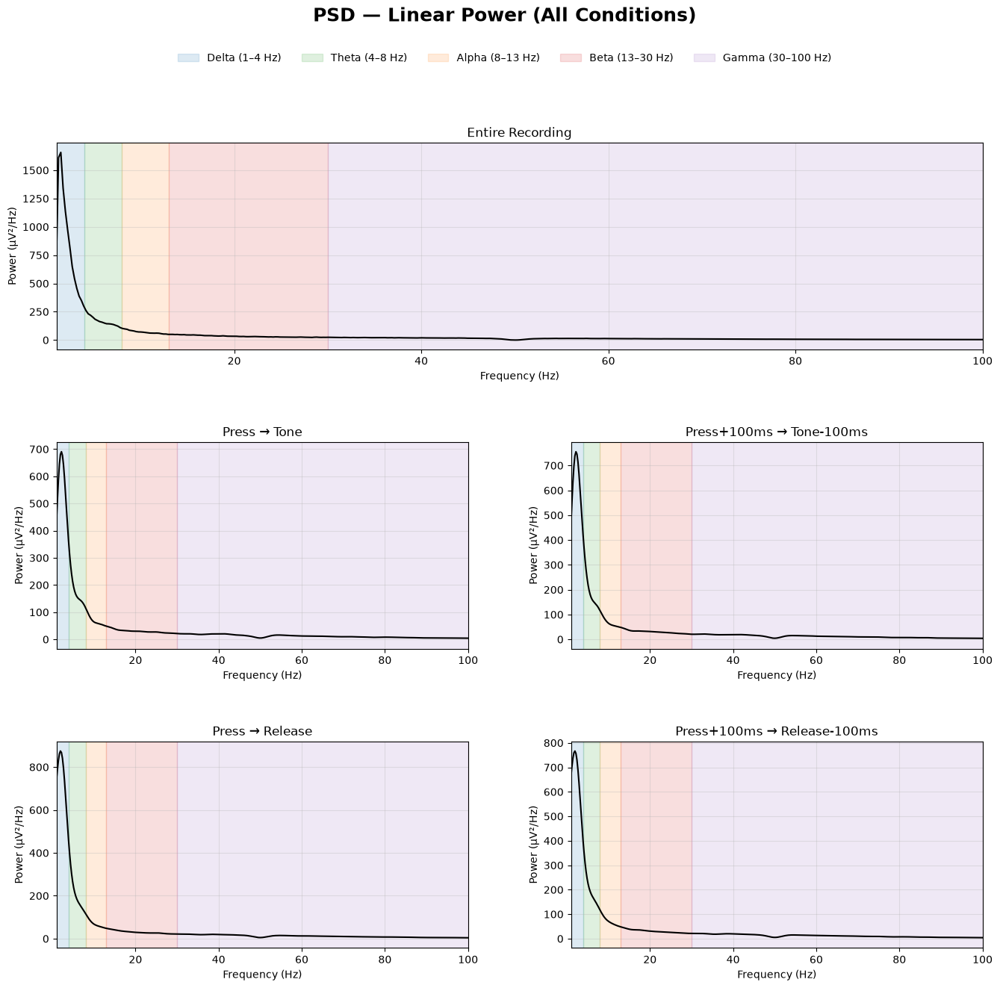

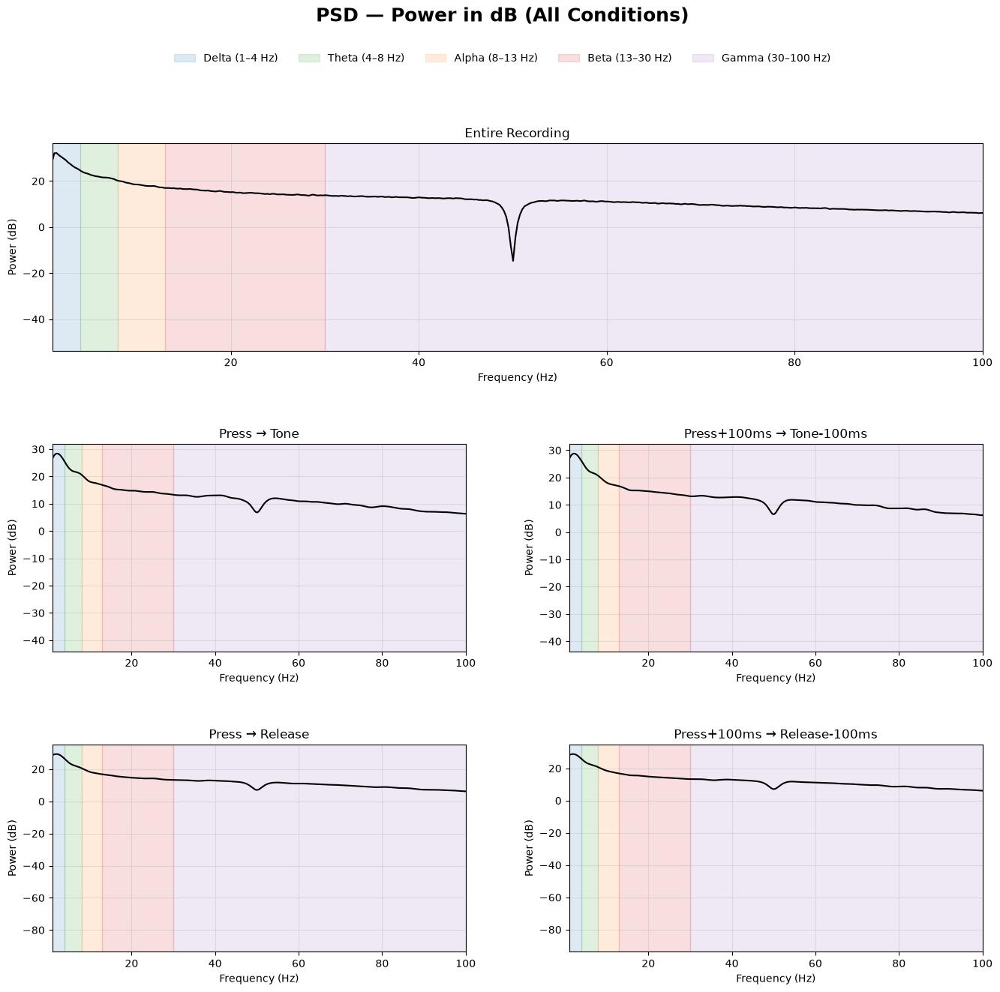

In [152]:
from matplotlib.gridspec import GridSpec
from pathlib import Path

bands = {
    'Delta (1–4 Hz)': (1, 4, 'tab:blue'),
    'Theta (4–8 Hz)': (4, 8, 'tab:green'),
    'Alpha (8–13 Hz)': (8, 13, 'tab:orange'),
    'Beta (13–30 Hz)': (13, 30, 'tab:red'),
    'Gamma (30–100 Hz)': (30, 100, 'tab:purple'),
}

conditions = [
    ("Entire Recording", ent_f, ent_psd, ent_psd_db),
    ("Press → Tone", tone_full_f, tone_full_psd, tone_full_psd_db),
    ("Press+100ms → Tone-100ms", tone_trim_f, tone_trim_psd, tone_trim_psd_db),
    ("Press → Release", rel_full_f, rel_full_psd, rel_full_psd_db),
    ("Press+100ms → Release-100ms", rel_trim_f, rel_trim_psd, rel_trim_psd_db),
]

out_dir = Path(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260522_r0000136_wt_1750\amir_data\entire_vs_event\no_CAR")
out_dir.mkdir(parents=True, exist_ok=True)


def build_figure(use_linear, ylabel, title, filename):
    fig = plt.figure(figsize=(16, 14))
    gs = GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.25)

    axes = [
        fig.add_subplot(gs[0, :]),
        fig.add_subplot(gs[1, 0]),
        fig.add_subplot(gs[1, 1]),
        fig.add_subplot(gs[2, 0]),
        fig.add_subplot(gs[2, 1]),
    ]

    band_patches = []

    for i, (name, freqs, psd, psd_db) in enumerate(conditions):
        ax = axes[i]

        ax.plot(
            freqs,
            psd if use_linear else psd_db,
            color="black",
            linewidth=1.5
        )

        ax.set_title(name, fontsize=12)
        ax.set_xlim(1, 100)
        ax.set_xlabel("Frequency (Hz)")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)

        for band_name, (fmin, fmax, color) in bands.items():
            patch = ax.axvspan(fmin, fmax, color=color, alpha=0.15)

            if i == 0:
                band_patches.append(patch)

    fig.suptitle(title, fontsize=18, fontweight="bold", y=1.01)

    fig.legend(
        handles=band_patches,
        labels=list(bands.keys()),
        loc="upper center",
        bbox_to_anchor=(0.5, 0.975),
        ncol=len(bands),
        frameon=False,
        fontsize=10,
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(out_dir / filename, dpi=300, bbox_inches="tight")
    plt.show()


# Linear power
build_figure(
    True,
    "Power (µV²/Hz)",
    "PSD — Linear Power (All Conditions)",
    "PSD_all_conditions_linear.png"
)

# dB power
build_figure(
    False,
    "Power (dB)",
    "PSD — Power in dB (All Conditions)",
    "PSD_all_conditions_db.png"
)

## Baseline corrected acc. to each event

In [11]:
#select the channel
channel_id = 'imec0.ap#AP0'

#time window
tmin_v1 = - 0.6 #before event
tmax_v1 = 1 #after event

#get no of samples for the window
n_pre_v1 = round(fs * abs(tmin_v1)) #before event
n_post_v1 = round(fs * tmax_v1) # after event
n_total_v1 = n_pre_v1 + n_post_v1 #Total no of samples for the whole window

#define frequencies that we need to analyze 
freqs_v1 = np.arange(1, 100, 1) 

#For each frequency, MNE takes a small oscillatory template (the Morlet wavelet) and slides it across your signal.
# asks: How strongly does the signal resemble a x Hz oscillation at this particular moment?
#how many cycles each morlet wavelet contains, higher frequencies use more cycles.
# increase number of cycles increases the frequency resolution cause you have more freq information
# but time resolution will be affected, for 1 cycle at 10 hz you get 0.1 s (1/10) nut if you increased to 10 cycles you will loose time percision as you will look at 1 second 

n_cycles_v1 = freqs_v1 / 2
#1 Hz  → 0.5 cycles
#10 Hz → 5 cycles
#20 Hz → 10 cycles
#50 Hz → 25 cycles
#99 Hz → 49.5 cycles

#create empyty dict.
results_own_v1 = {}

for name, column in {'Press': 'press_np_s', 'Tone': 'tone_np_s', 'Release': 'release_np_s'}.items():

    # get the column
    # remove the missing values with NaN
    # convert pandas series into numpyarray with . values
    # convert to number of samples *fs
    # convert to int
    align_idx = (l_C[column].dropna().values * fs).astype(int)

    
    arr_list = []

    # loop for every event
    for idx in align_idx:

        #calc when it will start and when to end
        start = idx - n_pre_v1
        end = idx + n_post_v1

        #Extract the actual neural signal
        #Give me the signal from start to end for channel imec0.ap#AP0. the signal returned in microvolts (µV)
        trace = ds_data.get_traces(start_frame=start, end_frame=end, channel_ids=[channel_id], return_in_uV=True)

        #only keep if window was complete
        if trace.shape[0] == n_total_v1:
            arr_list.append(trace[:, 0]) 

    #turn the list of valid trials into (events,ch,n_s)
    arr_3 = np.array(arr_list)[:,np.newaxis,:]
    
    #Create MNE channel information
    info = mne.create_info(ch_names=[channel_id], sfreq=fs, ch_types='seeg')

    #convert our shape to MNE object
    epochs = mne.EpochsArray(arr_3, info, tmin=tmin_v1, verbose=False)

    #Calc. Morlet TFR
    #use_fft=True: It generally makes the computation faster.
    #ITC means inter-trial coherence.
    #average: calculating the TFR across all your events and then averaging the TFR across epochs
    #decim=2: This downsamples the resulting TFR in time by a factor of 2. So you're keeping every second time point in the TFR. This reduces the amount of data and makes computation/storage easier
    #n_jobs: Use one CPU process.
    power = epochs.compute_tfr(method='morlet', freqs=freqs_v1, n_cycles=n_cycles_v1, use_fft=True, return_itc=False, average=True, decim=1, n_jobs=1, verbose=False)

    #Apply the baseline correction
    power.apply_baseline(baseline=(-0.5, -0.2), mode='logratio')

    #Save the Press/Tone/Release result
    results_own_v1[name] = power.data[0]
    #Save the time axis
    times_v1 = power.times

    print(name, power.data.shape)

NameError: name 'fs' is not defined

C:\Users\ar687\AppData\Local\Temp\ipykernel_24932\2253462020.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


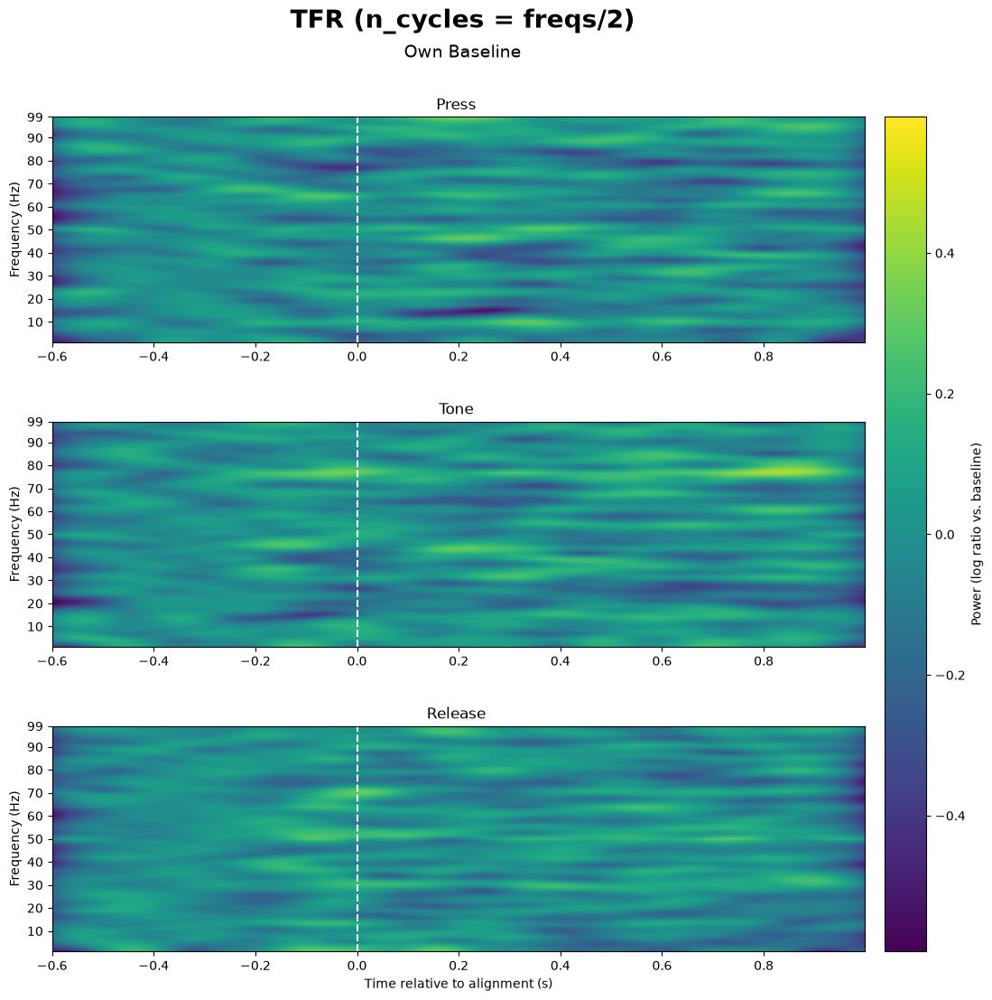

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True, sharey=True, gridspec_kw={'hspace': 0.35})

vmax = np.max(np.abs(np.concatenate([results_own_v1['Press'].ravel(), results_own_v1['Tone'].ravel(), results_own_v1['Release'].ravel()])))

for ax, name in zip(axes, ['Press', 'Tone', 'Release']):
    im = ax.imshow(results_own_v1[name], aspect='auto', origin='lower',
                    extent=[times_v1[0], times_v1[-1], freqs_v1[0], freqs_v1[-1]],
                    cmap='viridis', vmin=-vmax, vmax=vmax)
    ax.axvline(0, color='white', linestyle='--', linewidth=1.5)
    ax.set_ylabel('Frequency (Hz)')
    ax.set_title(f'{name} ')
    ax.tick_params(axis='x', labelbottom=True)
    ax.set_yticks([10, 20, 30, 40, 50, 60, 70, 80, 90, 99])
    ax.set_ylim(1, 99)

axes[-1].set_xlabel('Time relative to alignment (s)')
fig.suptitle('TFR (n_cycles = freqs/2)', fontsize=20, fontweight='bold', x=0.45, y=0.98)
fig.text(0.45, 0.935, 'Own Baseline', ha='center', fontsize=14)
cbar = fig.colorbar(im, ax=axes, pad=0.02)
cbar.set_label('Power (log ratio vs. baseline)')
plt.tight_layout()
plt.show()

## Baseline corrected acc. to Press 

In [ ]:
# Store raw (non-baseline-corrected) TFR objects for each condition
raw_power_v1 = {}

# Loop through Press, Tone, and Release event columns
for name, column in {'Press': 'press_np_s', 'Tone': 'tone_np_s', 'Release': 'release_np_s'}.items():

    # Convert event times from seconds to sample indices
    align_idx = (l_C[column].dropna().values * fs).astype(int)

    # Store valid extracted trials
    arr_list = []

    # Extract one epoch around each event
    for idx in align_idx:

        # Define epoch start and end samples
        start, end = idx - n_pre_v1, idx + n_post_v1

        # Extract the signal for the selected channel
        trace = ds_data.get_traces(start_frame=start, end_frame=end, channel_ids=[channel_id], return_in_uV=True)

        # Keep only epochs with the expected number of samples
        if trace.shape[0] == n_total_v1: arr_list.append(trace[:, 0])

    # Convert trials to MNE shape: (n_epochs, n_channels, n_times)
    arr_3 = np.array(arr_list)[:, np.newaxis, :]

    # Create MNE channel information
    info = mne.create_info(ch_names=[channel_id], sfreq=fs, ch_types='seeg')

    # Create MNE EpochsArray using the extracted trials
    epochs = mne.EpochsArray(arr_3, info, tmin=tmin_v1, verbose=False)

    # Compute Morlet time-frequency power without baseline correction
    power = epochs.compute_tfr(method='morlet', freqs=freqs_v1, n_cycles=n_cycles_v1, use_fft=True, return_itc=False, average=True, decim=1, n_jobs=1, verbose=False)

    # Store the raw TFR under its condition name
    raw_power_v1[name] = power

    # Print the condition and resulting TFR shape
    print(name, power.data.shape)

Press (1, 99, 1600)
Tone (1, 99, 1600)
Release (1, 99, 1600)


In [ ]:
print(raw_power_v1.keys())

dict_keys(['Press', 'Tone', 'Release'])


In [ ]:
# baseline window: 500 to 200 ms before PRESS
baseline_win = (-0.5, -0.2)

press_times_v1 = raw_power_v1['Press'].times
b_mask_v1 = (press_times_v1 >= baseline_win[0]) & (press_times_v1 <= baseline_win[1])

# mean power per frequency across the Press baseline window
# shape: (n_channels, n_freqs, n_baseline_samples) -> (n_channels, n_freqs, 1)
baseline_power_v1= raw_power_v1['Press'].data[:, :, b_mask_v1].mean(axis=-1, keepdims=True)

# apply this single baseline (logratio) to Press, Tone, and Release
results_press_v1 = {}
for name, power in raw_power_v1.items():
    results_press_v1[name] = np.log10(power.data / baseline_power_v1)[0]  # channel 0

# time axis is identical across conditions (same tmin/tmax/fs for all)
times_v1 = raw_power_v1['Press'].times

C:\Users\ar687\AppData\Local\Temp\ipykernel_24932\2871734819.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


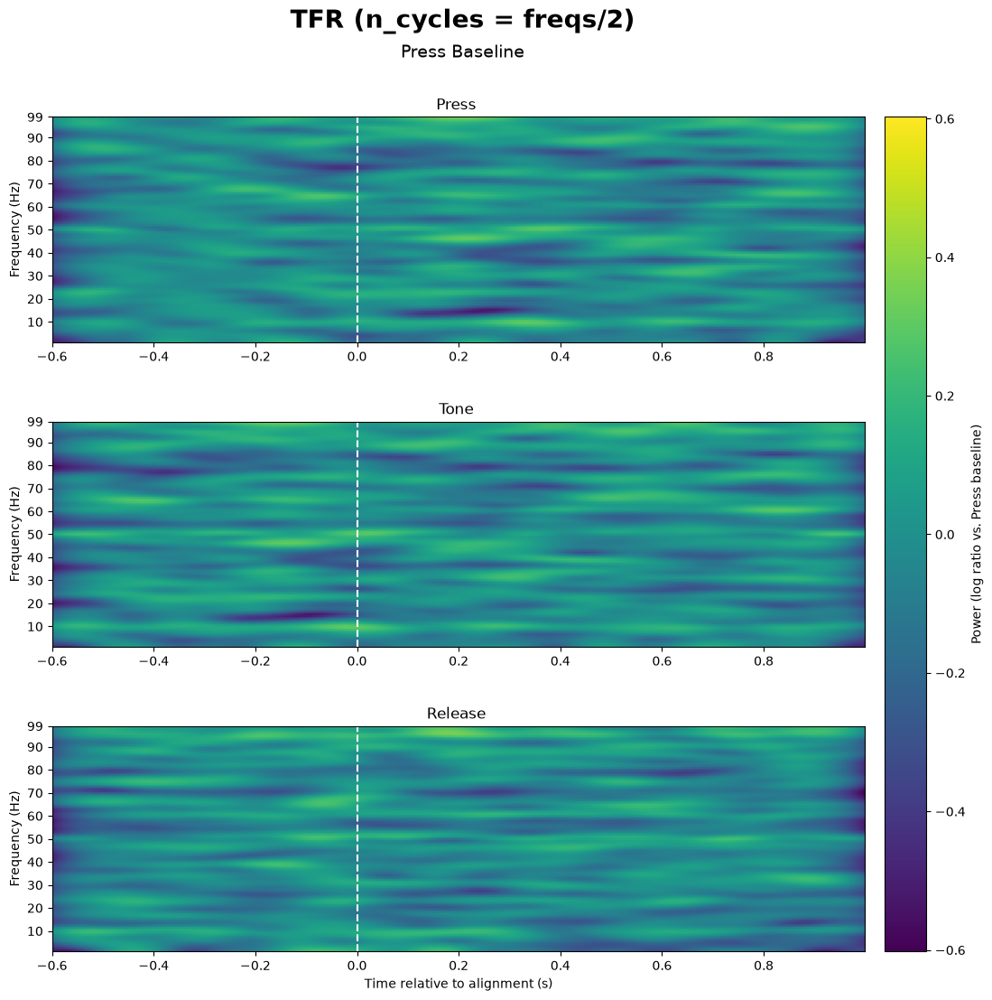

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True, sharey=True, gridspec_kw={'hspace': 0.35})

vmax = np.max(np.abs(np.concatenate([results_press_v1['Press'].ravel(), results_press_v1['Tone'].ravel(), results_press_v1['Release'].ravel()])))

for ax, name in zip(axes, ['Press', 'Tone', 'Release']):
    im = ax.imshow(results_press_v1[name], aspect='auto', origin='lower',
                    extent=[times_v1[0], times_v1[-1], freqs_v1[0], freqs_v1[-1]],
                    cmap='viridis', vmin=-vmax, vmax=vmax)
    ax.axvline(0, color='white', linestyle='--', linewidth=1.5)
    ax.set_ylabel('Frequency (Hz)')
    ax.set_title(f'{name} ')
    ax.tick_params(axis='x', labelbottom=True)
    ax.set_yticks([10, 20, 30, 40, 50, 60, 70, 80, 90, 99])
    ax.set_ylim(1, 99)

axes[-1].set_xlabel('Time relative to alignment (s)')
fig.suptitle('TFR (n_cycles = freqs/2)', fontsize=20, fontweight='bold', x=0.45, y=0.98)
fig.text(0.45, 0.935, 'Press Baseline', ha='center', fontsize=14)
cbar = fig.colorbar(im, ax=axes, pad=0.02)
cbar.set_label('Power (log ratio vs. Press baseline)')
plt.tight_layout()
plt.show()

## Compare Basline correction Methods

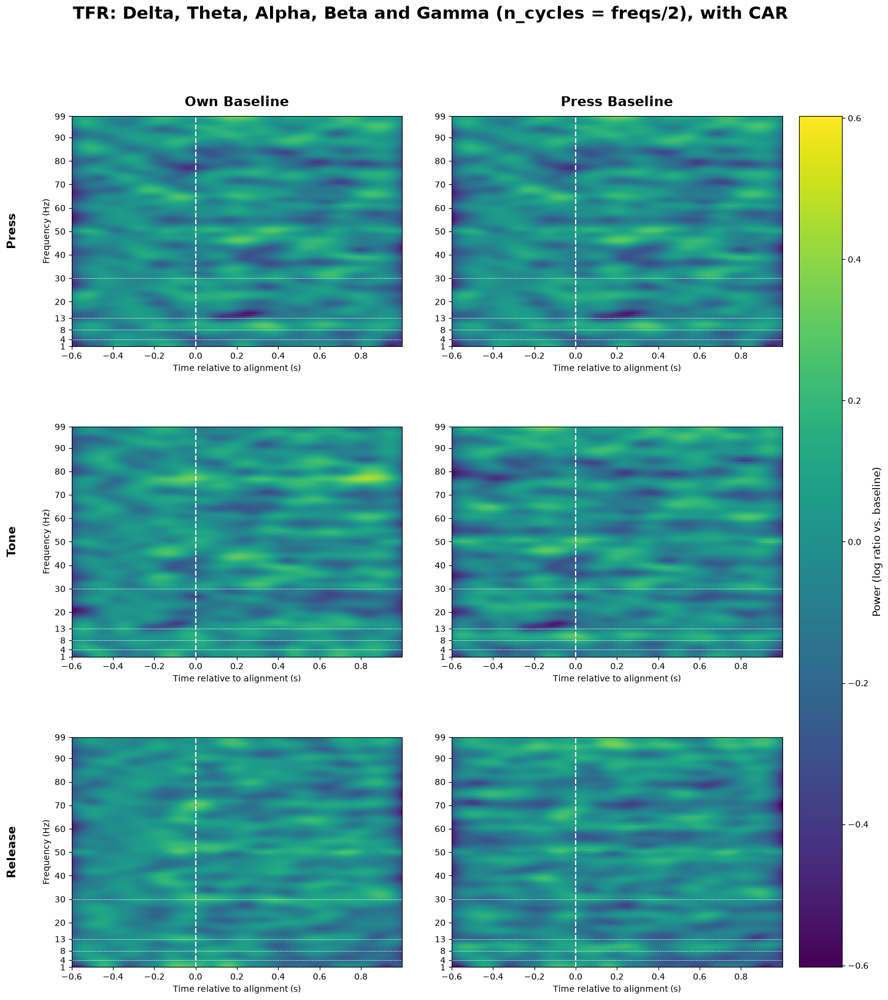

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(18, 18), sharex=True, sharey=True, gridspec_kw={'hspace': 0.35, 'wspace': 0.15})

vmax = np.max(np.abs(np.concatenate([
    results_own_v1['Press'].ravel(), results_own_v1['Tone'].ravel(), results_own_v1['Release'].ravel(),   # <-- CHECK: results_own_v1
    results_press_v1['Press'].ravel(), results_press_v1['Tone'].ravel(), results_press_v1['Release'].ravel()   # <-- CHECK: results_press_v1
])))

row_names = ['Press', 'Tone', 'Release']

for row, name in enumerate(row_names):

    im = axes[row, 0].imshow(results_own_v1[name], aspect='auto', origin='lower',   # <-- CHECK: results_own_v1
                              extent=[times_v1[0], times_v1[-1], freqs_v1[0], freqs_v1[-1]],
                              cmap='viridis', vmin=-vmax, vmax=vmax)
    axes[row, 0].axvline(0, color='white', linestyle='--', linewidth=1.5)
    axes[row, 0].axhline(4, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].axhline(8, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].axhline(13, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].axhline(30, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].set_ylabel('Frequency (Hz)')
    axes[row, 0].text(-0.18, 0.5, name, transform=axes[row, 0].transAxes, rotation=90, va='center', ha='center', fontsize=14, fontweight='bold')
    axes[row, 0].set_yticks([1, 4, 8, 13, 20, 30, 40, 50, 60, 70, 80, 90, 99])
    axes[row, 0].set_ylim(1, 99)
    axes[row, 0].set_xlabel('Time relative to alignment (s)')
    axes[row, 0].tick_params(axis='x', which='both', labelbottom=True)

    axes[row, 1].imshow(results_press_v1[name], aspect='auto', origin='lower',   # <-- CHECK: results_press_v1
                         extent=[times_v1[0], times_v1[-1], freqs_v1[0], freqs_v1[-1]],
                         cmap='viridis', vmin=-vmax, vmax=vmax)
    axes[row, 1].axvline(0, color='white', linestyle='--', linewidth=1.5)
    axes[row, 1].axhline(4, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].axhline(8, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].axhline(13, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].axhline(30, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].set_yticks([1, 4, 8, 13, 20, 30, 40, 50, 60, 70, 80, 90, 99])
    axes[row, 1].set_ylim(1, 99)
    axes[row, 1].set_xlabel('Time relative to alignment (s)')
    axes[row, 1].tick_params(axis='x', which='both', labelbottom=True)

    axes[row, 0].tick_params(axis='y', which='both', labelleft=True)
    axes[row, 1].tick_params(axis='y', which='both', labelleft=True)

axes[0, 0].set_title('Own Baseline', fontsize=16, fontweight='bold', pad=12)
axes[0, 1].set_title('Press Baseline', fontsize=16, fontweight='bold', pad=12)

fig.suptitle('TFR: Delta, Theta, Alpha, Beta and Gamma (n_cycles = freqs/2), with CAR', fontsize=20, fontweight='bold', x=0.45, y=0.98)

cbar = fig.colorbar(im, ax=axes, pad=0.02)
cbar.set_label('Power (log ratio vs. baseline)', fontsize=12)
#plt.savefig(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260513_r0000136_wt_1729\amir_data\Time_Frequency_Analysis\with_CAR\n_cycles = f over 2\Morlet_wavelet_with_CAR.png", dpi=300, bbox_inches="tight")
plt.show()


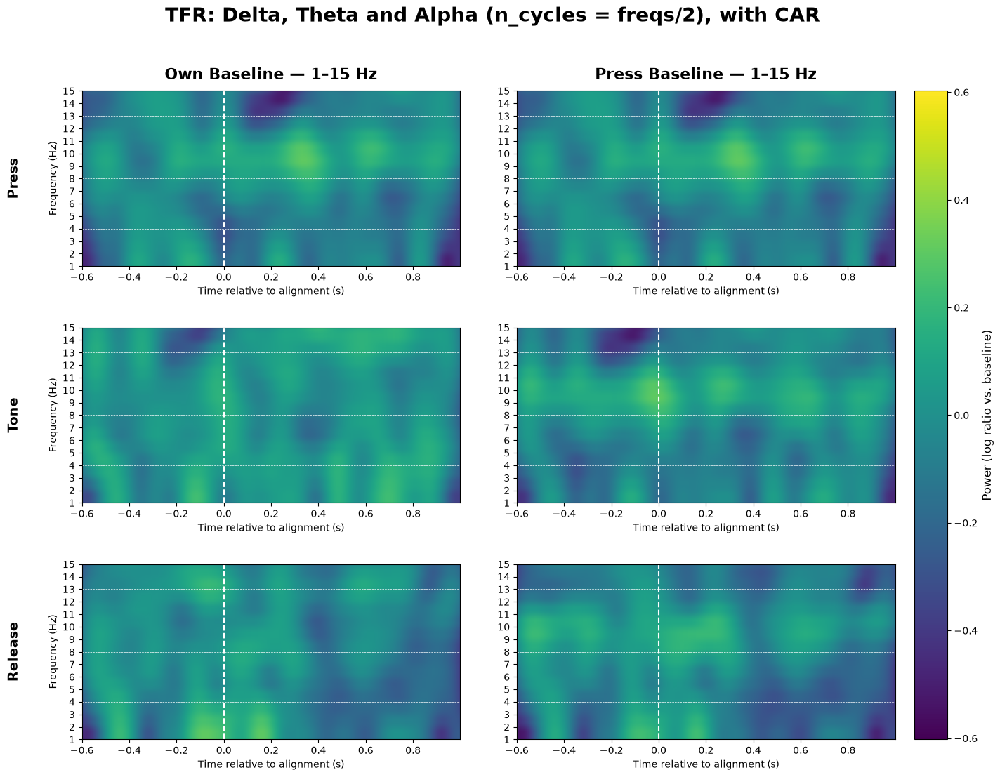

In [ ]:
# vmax is not computed in this cell at all — CHECK: it must be defined before use, or you'll get a NameError
vmax = np.max(np.abs(np.concatenate([
    results_own_v1['Press'].ravel(), results_own_v1['Tone'].ravel(), results_own_v1['Release'].ravel(),
    results_press_v1['Press'].ravel(), results_press_v1['Tone'].ravel(), results_press_v1['Release'].ravel()
])))

fig, axes = plt.subplots(3, 2, figsize=(18, 12), sharex=True, sharey=True, gridspec_kw={'hspace': 0.35, 'wspace': 0.15})

row_names = ['Press', 'Tone', 'Release']

for row, name in enumerate(row_names):

    im = axes[row, 0].imshow(results_own_v1[name], aspect='auto', origin='lower',   # <-- CHECK: results_own_v1
                              extent=[times_v1[0], times_v1[-1], freqs_v1[0], freqs_v1[-1]],   # <-- CHECK: times_v1, freqs_v1
                              cmap='viridis', vmin=-vmax, vmax=vmax)

    axes[row, 0].axvline(0, color='white', linestyle='--', linewidth=1.5)
    axes[row, 0].axhline(4, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].axhline(8, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].axhline(13, color='white', linestyle='--', linewidth=0.5)

    axes[row, 0].set_ylabel('Frequency (Hz)')
    axes[row, 0].text(-0.18, 0.5, name, transform=axes[row, 0].transAxes, rotation=90, va='center', ha='center', fontsize=14, fontweight='bold')
    axes[row, 0].set_yticks([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15])
    axes[row, 0].set_ylim(1, 15)
    axes[row, 0].set_xlabel('Time relative to alignment (s)')
    axes[row, 0].tick_params(axis='x', which='both', labelbottom=True)

    axes[row, 1].imshow(results_press_v1[name], aspect='auto', origin='lower',   # <-- CHECK: results_press_v1
                         extent=[times_v1[0], times_v1[-1], freqs_v1[0], freqs_v1[-1]],   # <-- CHECK: times_v1, freqs_v1
                         cmap='viridis', vmin=-vmax, vmax=vmax)

    axes[row, 1].axvline(0, color='white', linestyle='--', linewidth=1.5)
    axes[row, 1].axhline(4, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].axhline(8, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].axhline(13, color='white', linestyle='--', linewidth=0.5)

    axes[row, 1].set_yticks([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15])
    axes[row, 1].set_ylim(1, 15)
    axes[row, 1].set_xlabel('Time relative to alignment (s)')
    axes[row, 1].tick_params(axis='x', which='both', labelbottom=True)

    axes[row, 0].tick_params(axis='y', which='both', labelleft=True)
    axes[row, 1].tick_params(axis='y', which='both', labelleft=True)

axes[0, 0].set_title('Own Baseline — 1–15 Hz', fontsize=16, fontweight='bold', pad=12)
axes[0, 1].set_title('Press Baseline — 1–15 Hz', fontsize=16, fontweight='bold', pad=12)

fig.suptitle('TFR: Delta, Theta and Alpha (n_cycles = freqs/2), with CAR', fontsize=20, fontweight='bold', x=0.45, y=0.98)

cbar = fig.colorbar(im, ax=axes, pad=0.02)
cbar.set_label('Power (log ratio vs. baseline)', fontsize=12)

#plt.savefig(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260513_r0000136_wt_1729\amir_data\Time_Frequency_Analysis\with_CAR\n_cycles = f over 2\Morlet_wavelet_zoom_with_CAR.png", dpi=300, bbox_inches="tight")

plt.show()

## Across channels

In [ ]:
ds_data.get_probe().to_dataframe()

,x,y,contact_shapes,width,shank_ids,contact_ids
0,250.0,2160.0,square,12.0,1,s1e288
1,32.0,2880.0,square,12.0,0,s0e385
2,250.0,2175.0,square,12.0,1,s1e290
3,32.0,2895.0,square,12.0,0,s0e387
4,250.0,2190.0,square,12.0,1,s1e292
...,...,...,...,...,...,...
378,32.0,2115.0,square,12.0,0,s0e283
379,500.0,2850.0,square,12.0,2,s2e380
380,32.0,2130.0,square,12.0,0,s0e285
381,500.0,2865.0,square,12.0,2,s2e382


shank_ids  shank_channel     channel_id contact_ids     x      y
        1            126  imec0.ap#AP34      s1e322 250.0 2415.0
        0             84  imec0.ap#AP41      s0e425  32.0 3180.0
        1              0  imec0.ap#AP49        s1e1 282.0    0.0
        1            168  imec0.ap#AP72      s1e408 250.0 3060.0
        1             21  imec0.ap#AP91       s1e43 282.0  315.0
        1            147 imec0.ap#AP124      s1e364 250.0 2730.0
        0            105 imec0.ap#AP131      s0e467  32.0 3495.0
        0             42 imec0.ap#AP149      s0e341  32.0 2550.0
        0             63 imec0.ap#AP191      s0e383  32.0 2865.0
        2             42 imec0.ap#AP214      s2e406 500.0 3045.0
        2              0 imec0.ap#AP241      s2e289 532.0 2160.0
        1             42 imec0.ap#AP242       s1e98 250.0  735.0
        0              0 imec0.ap#AP257      s0e209  32.0 1560.0
        1             63 imec0.ap#AP284      s1e140 250.0 1050.0
        1             84 

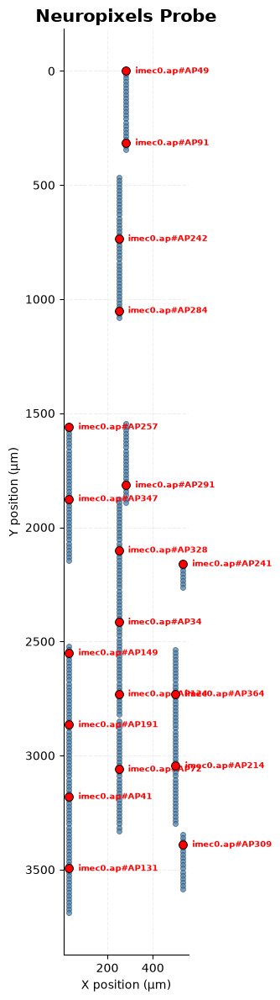

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

probe = ds_data.get_probe()
df = probe.to_dataframe().copy()

# Map each probe contact to its ACTUAL recording channel ID
channel_ids = ds_data.get_channel_ids()

df["channel_id"] = [
    channel_ids[i] for i in probe.device_channel_indices
]

# Number contacts physically along each shank
df["shank_channel"] = (
    df.sort_values(["shank_ids", "y"])
      .groupby("shank_ids")
      .cumcount()
)

# Every 21st physical channel on EACH shank
highlighted = df[df["shank_channel"] % 21 == 0]

# Check selected channels
print(
    highlighted[
        ["shank_ids", "shank_channel", "channel_id",
         "contact_ids", "x", "y"]
    ].to_string(index=False)
)


# Plot
fig, ax = plt.subplots(figsize=(10, 12))

# All probe contacts
ax.scatter(
    df["x"],
    df["y"],
    s=20,
    color="steelblue",
    edgecolor="black",
    linewidth=0.3,
    alpha=0.75,
)

# Selected contacts
ax.scatter(
    highlighted["x"],
    highlighted["y"],
    s=50,
    color="red",
    edgecolor="black",
    linewidth=0.7,
    zorder=5,
)

# Label with ACTUAL channel ID
for _, row in highlighted.iterrows():
    ax.annotate(
        row["channel_id"],       # e.g. imec0.ap#AP147
        (row["x"], row["y"]),
        xytext=(8, 0),
        textcoords="offset points",
        fontsize=7,
        color="red",
        fontweight="bold",
        va="center",
    )

ax.invert_yaxis()
ax.set_aspect("equal", adjustable="box")

ax.set_xlabel("X position (µm)")
ax.set_ylabel("Y position (µm)")
ax.set_title(
    "Neuropixels Probe",
    fontsize=15,
    fontweight="bold",
)

ax.grid(alpha=0.2, linestyle="--")
sns.despine()
#plt.savefig(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260513_r0000136_wt_1729\amir_data\Time_Frequency_Analysis\with_CAR\Probe.png", dpi=300, bbox_inches="tight")

plt.tight_layout()
plt.show()

In [ ]:
selected_df = highlighted.reset_index(drop=True)
all_results_v1 = {}   
for _, row in selected_df.iterrows():
    channel_id = row['channel_id']
    raw_power = {}
    for name, column in {'Press': 'press_np_s', 'Tone': 'tone_np_s', 'Release': 'release_np_s'}.items():
        align_idx = (l_C[column].dropna().values * fs).astype(int)
        arr_list = []
        for idx in align_idx:
            start, end = idx - n_pre_v1, idx + n_post_v1   # <-- CHECK: n_pre_v1, n_post_v1
            trace = ds_data.get_traces(start_frame=start, end_frame=end, channel_ids=[channel_id], return_in_uV=True)
            if trace.shape[0] == n_total_v1: arr_list.append(trace[:, 0])   # <-- CHECK: n_total_v1
        arr_3 = np.array(arr_list)[:, np.newaxis, :]
        info = mne.create_info(ch_names=[channel_id], sfreq=fs, ch_types='seeg')
        epochs = mne.EpochsArray(arr_3, info, tmin=tmin_v1, verbose=False)   # <-- CHECK: tmin_v1
        power = epochs.compute_tfr(method='morlet', freqs=freqs_v1, n_cycles=n_cycles_v1,   # <-- CHECK: freqs_v1, n_cycles_v1
                                    use_fft=True, return_itc=False, average=True,
                                    decim=1, n_jobs=1, verbose=False)
        raw_power[name] = power
    press_times = raw_power['Press'].times
    b_mask = (press_times >= -0.5) & (press_times <= -0.2)
    baseline_power = raw_power['Press'].data[:, :, b_mask].mean(axis=-1, keepdims=True)
    all_results_v1[channel_id] = {name: np.log10(power.data / baseline_power)[0] for name, power in raw_power.items()}   # <-- CHECK: all_results_v1
    print(f"Done: {channel_id}")

times_multi_v1 = raw_power['Press'].times   

Done: imec0.ap#AP34
Done: imec0.ap#AP41
Done: imec0.ap#AP49
Done: imec0.ap#AP72
Done: imec0.ap#AP91
Done: imec0.ap#AP124
Done: imec0.ap#AP131
Done: imec0.ap#AP149
Done: imec0.ap#AP191
Done: imec0.ap#AP214
Done: imec0.ap#AP241
Done: imec0.ap#AP242
Done: imec0.ap#AP257
Done: imec0.ap#AP284
Done: imec0.ap#AP291
Done: imec0.ap#AP309
Done: imec0.ap#AP328
Done: imec0.ap#AP347
Done: imec0.ap#AP364


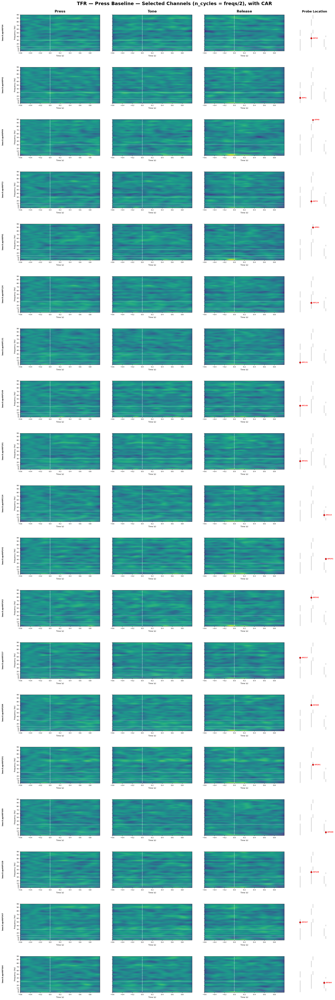

In [ ]:
n_channels = len(selected_df)
conditions = ['Press', 'Tone', 'Release']
frequency_ticks = [1, 4, 8, 13, 20, 30, 40, 50, 60, 70, 80, 90, 99]
oscillation_boundaries = [4, 8, 13, 30]

all_values = np.concatenate([all_results_v1[ch][cond].ravel()[np.isfinite(all_results_v1[ch][cond].ravel())] for ch in all_results_v1 for cond in conditions])
# <-- CHECK: all_results_v1 (both places)
vmax = np.max(np.abs(all_values))

probe = ds_data.get_probe()
probe_df = probe.to_dataframe().copy()
channel_ids = ds_data.get_channel_ids()
probe_df['channel_id'] = [channel_ids[i] for i in probe.device_channel_indices]

fig, axes = plt.subplots(n_channels, 4, figsize=(22, 3.2 * n_channels), gridspec_kw={'width_ratios': [1, 1, 1, 0.45], 'wspace': 0.18, 'hspace': 0.45})

if n_channels == 1: axes = axes[np.newaxis, :]

for row, (_, channel_row) in enumerate(selected_df.iterrows()):
    channel_id = channel_row['channel_id']
    channel_x = channel_row['x']
    channel_y = channel_row['y']

    for col, condition in enumerate(conditions):
        ax = axes[row, col]
        im = ax.imshow(all_results_v1[channel_id][condition], aspect='auto', origin='lower',   # <-- CHECK: all_results_v1
                        extent=[times_multi_v1[0], times_multi_v1[-1], freqs_v1[0], freqs_v1[-1]],   # <-- CHECK: times_multi_v1, freqs_v1
                        cmap='viridis', vmin=-vmax, vmax=vmax, interpolation='bilinear')
        ax.axvline(0, color='white', linestyle='--', linewidth=1.2)
        [ax.axhline(f, color='white', linestyle='--', linewidth=0.6) for f in oscillation_boundaries]
        ax.set_ylim(1, 99)
        ax.set_yticks(frequency_ticks)
        ax.set_xlim(times_multi_v1[0], times_multi_v1[-1])   # <-- CHECK: times_multi_v1
        ax.grid(False)
        ax.tick_params(axis='both', which='both', length=3, labelsize=7)
        ax.set_xlabel('Time (s)', fontsize=8)

        if col == 0:
            ax.set_ylabel('Frequency (Hz)', fontsize=8)
            ax.text(-0.22, 0.5, channel_id, transform=ax.transAxes, rotation=90, va='center', ha='center', fontsize=8, fontweight='bold')
        else:
            ax.set_ylabel('')
            ax.tick_params(axis='y', labelleft=False)

    ax_probe = axes[row, 3]
    ax_probe.scatter(probe_df['x'], probe_df['y'], s=7, color='lightgray', edgecolors='none')
    ax_probe.scatter(channel_x, channel_y, s=50, color='red', edgecolors='black', linewidths=0.5, zorder=10)
    ax_probe.text(channel_x + 30, channel_y, channel_id.replace('imec0.ap#AP', 'AP'), color='red', fontsize=7, fontweight='bold', va='center', zorder=11)
    ax_probe.set_xlim(probe_df['x'].min() - 70, probe_df['x'].max() + 130)
    ax_probe.set_ylim(probe_df['y'].max() + 40, probe_df['y'].min() - 40)
    ax_probe.set_xticks([])
    ax_probe.set_yticks([])
    ax_probe.grid(False)
    ax_probe.set_xlabel('')
    ax_probe.set_ylabel('')
    [spine.set_visible(False) for spine in ax_probe.spines.values()]

axes[0, 0].set_title('Press', fontsize=15, fontweight='bold', pad=10)
axes[0, 1].set_title('Tone', fontsize=15, fontweight='bold', pad=10)
axes[0, 2].set_title('Release', fontsize=15, fontweight='bold', pad=10)
axes[0, 3].set_title('Probe Location', fontsize=13, fontweight='bold', pad=10)

fig.suptitle('TFR — Press Baseline — Selected Channels (n_cycles = freqs/2), with CAR', fontsize=20, fontweight='bold', y=0.998)

plt.subplots_adjust(left=0.08, right=0.93, top=0.985, bottom=0.025, wspace=0.15, hspace=0.45)

plt.savefig(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260513_r0000136_wt_1729\amir_data\Time_Frequency_Analysis\with_CAR\n_cycles = f over 2\Morlet_wavelet_across channels_with_CAR.png", dpi=300, bbox_inches="tight")

plt.show()

## Baseline corrected acc. to each event

In [56]:
#select the channel
channel_id = 'imec0.ap#AP0'

#time window for extraction - needs to be wide enough for the LOWEST freq + n_cycles combo used below
tmin_v2 = -3   #before event
tmax_v2 = 3    #after event

#get no of samples for the window
n_pre_v2 = round(fs * abs(tmin_v2)) #before event
n_post_v2 = round(fs * tmax_v2) # after event
n_total_v2 = n_pre_v2 + n_post_v2 #Total no of samples for the whole window

#define frequency bands, each with its own n_cycles tuned for that band
#lower n_cycles at low freqs = shorter wavelet = fits in our window, but less freq precision there
#higher n_cycles at high freqs = sharper freq resolution, costs little time resolution since wavelets are short anyway
band_settings = [
    {'freqs': np.arange(1, 4, 1),    'n_cycles': 2},   # delta
    {'freqs': np.arange(4, 8, 1),    'n_cycles': 5},   # theta
    {'freqs': np.arange(8, 13, 1),   'n_cycles': 6},   # alpha
    {'freqs': np.arange(13, 30, 1),  'n_cycles': 7},   # beta
    {'freqs': np.arange(30, 100, 1), 'n_cycles': 10},  # gamma
]

#create empty dict for final results
results_own_v2 = {}

for name, column in {'Press': 'press_np_s', 'Tone': 'tone_np_s', 'Release': 'release_np_s'}.items():

    # get the column
    # remove the missing values with NaN
    # convert pandas series into numpyarray with . values
    # convert to number of samples *fs
    # convert to int
    align_idx = (l_C[column].dropna().values * fs).astype(int)

    arr_list = []

    # loop for every event
    for idx in align_idx:

        #calc when it will start and when to end
        start = idx - n_pre_v2
        end = idx + n_post_v2

        #Extract the actual neural signal
        #Give me the signal from start to end for channel imec0.ap#AP0. the signal returned in microvolts (µV)
        trace = ds_data.get_traces(start_frame=start, end_frame=end, channel_ids=[channel_id], return_in_uV=True)

        #only keep if window was complete
        if trace.shape[0] == n_total_v2:
            arr_list.append(trace[:, 0])

    #turn the list of valid trials into (events,ch,n_s)
    arr_3 = np.array(arr_list)[:, np.newaxis, :]

    #Create MNE channel information
    info = mne.create_info(ch_names=[channel_id], sfreq=fs, ch_types='seeg')

    #convert our shape to MNE object - built ONCE per event, reused across all bands
    epochs = mne.EpochsArray(arr_3, info, tmin=tmin_v2, verbose=False)

    #compute TFR separately for each band, then stitch together
    band_power_list = []
    band_freqs_list = []

    for band in band_settings:
        power = epochs.compute_tfr(method='morlet',freqs=band['freqs'],n_cycles=band['n_cycles'],use_fft=True,return_itc=False,average=True,decim=1,n_jobs=1,verbose=False)

        #Apply the baseline correction (per band, since each has its own data)
        power.apply_baseline(baseline=(-0.5, -0.2), mode='logratio')

        #crop back down to the window we actually care about
        power.crop(tmin=-0.6, tmax=1)

        band_power_list.append(power.data[0])   # (n_freqs_in_band, n_times)
        band_freqs_list.append(band['freqs'])

    #stitch all bands into one combined array along the frequency axis
    combined_power = np.concatenate(band_power_list, axis=0)   # (total_freqs, n_times)
    combined_freqs = np.concatenate(band_freqs_list)

    #Save the Press/Tone/Release result
    results_own_v2[name] = combined_power
    #Save the time axis (same across bands since crop window is identical)
    times_v2 = power.times
    freqs_v2 = combined_freqs   # save once, same for every event

    print(name, combined_power.shape)

Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Press (99, 1601)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Tone (99, 1601)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Release (99, 1601)


C:\Users\ar687\AppData\Local\Temp\ipykernel_23972\1518813914.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


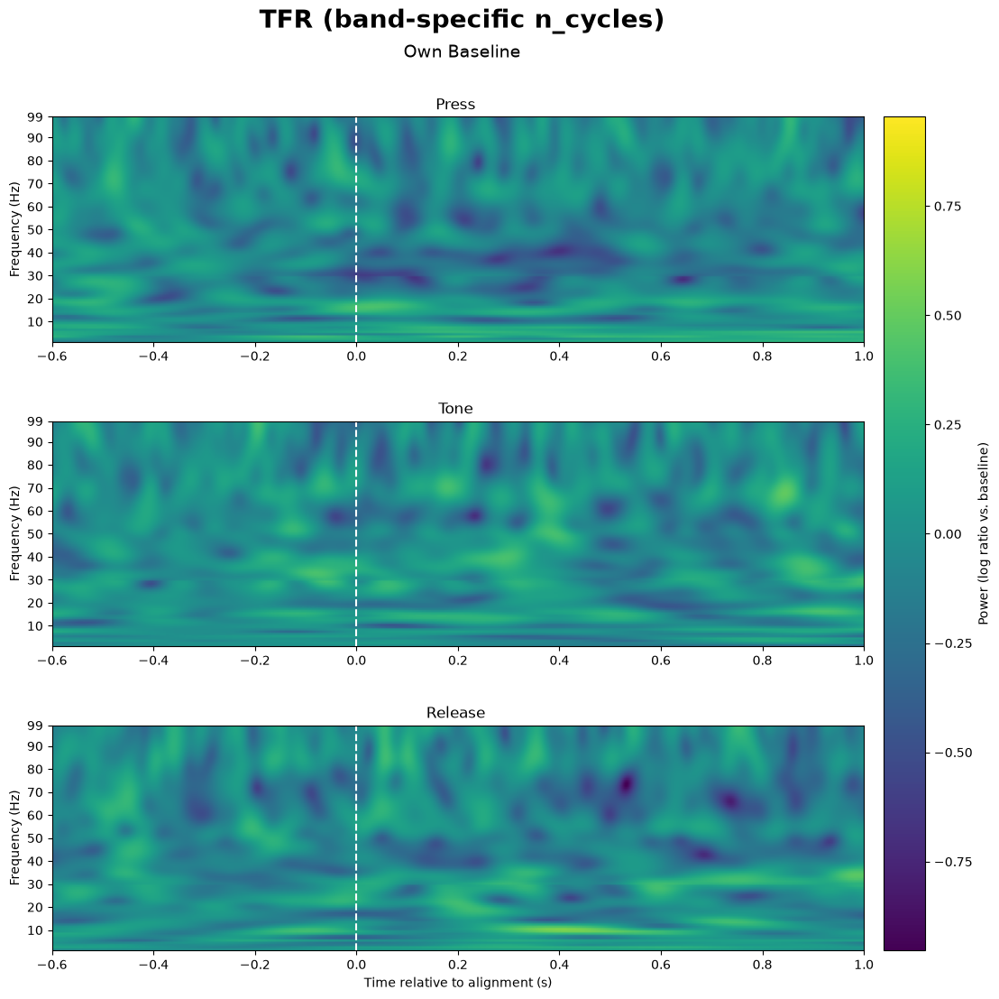

In [57]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True, sharey=True, gridspec_kw={'hspace': 0.35})

vmax = np.max(np.abs(np.concatenate([results_own_v2['Press'].ravel(), results_own_v2['Tone'].ravel(), results_own_v2['Release'].ravel()])))
# <-- CHECK: results_own_v2 (all three)

for ax, name in zip(axes, ['Press', 'Tone', 'Release']):
    im = ax.imshow(results_own_v2[name], aspect='auto', origin='lower',   # <-- CHECK: results_own_v2
                    extent=[times_v2[0], times_v2[-1], freqs_v2[0], freqs_v2[-1]],
                    cmap='viridis', vmin=-vmax, vmax=vmax)
    ax.axvline(0, color='white', linestyle='--', linewidth=1.5)
    ax.set_ylabel('Frequency (Hz)')
    ax.set_title(f'{name} ')
    ax.tick_params(axis='x', labelbottom=True)
    ax.set_yticks([10, 20, 30, 40, 50, 60, 70, 80, 90, 99])
    ax.set_ylim(1, 99)

axes[-1].set_xlabel('Time relative to alignment (s)')
fig.suptitle('TFR (band-specific n_cycles)', fontsize=20, fontweight='bold', x=0.45, y=0.98)
fig.text(0.45, 0.935, 'Own Baseline', ha='center', fontsize=14)
cbar = fig.colorbar(im, ax=axes, pad=0.02)
cbar.set_label('Power (log ratio vs. baseline)')
plt.tight_layout()
plt.show()

## Baseline corrected acc. to press

In [58]:
raw_power_v2 = {}  # name -> list of power objects, one per band

for name, column in {'Press': 'press_np_s', 'Tone': 'tone_np_s', 'Release': 'release_np_s'}.items():

    align_idx = (l_C[column].dropna().values * fs).astype(int)
    arr_list = []

    for idx in align_idx:
        start, end = idx - n_pre_v2, idx + n_post_v2
        trace = ds_data.get_traces(start_frame=start, end_frame=end, channel_ids=[channel_id], return_in_uV=True)
        if trace.shape[0] == n_total_v2:
            arr_list.append(trace[:, 0])

    arr_3 = np.array(arr_list)[:, np.newaxis, :]
    info = mne.create_info(ch_names=[channel_id], sfreq=fs, ch_types='seeg')
    epochs = mne.EpochsArray(arr_3, info, tmin=tmin_v2, verbose=False)

    band_power_objs = []
    for band in band_settings:
        power = epochs.compute_tfr(method='morlet', freqs=band['freqs'], n_cycles=band['n_cycles'],
                                    use_fft=True, return_itc=False, average=True,
                                    decim=1, n_jobs=1, verbose=False)
        band_power_objs.append(power)

    raw_power_v2[name] = band_power_objs
    print(name, [p.data.shape for p in band_power_objs])

Press [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Tone [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Release [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]


In [59]:
baseline_win = (-0.5, -0.2)
crop_win = (-0.6, 1)

results_press_v2 = {name: [] for name in ['Press', 'Tone', 'Release']}  

for b_idx, band in enumerate(band_settings):

    press_power_band = raw_power_v2['Press'][b_idx]
    press_times_band = press_power_band.times
    b_mask = (press_times_band >= baseline_win[0]) & (press_times_band <= baseline_win[1])
    baseline_power_band = press_power_band.data[:, :, b_mask].mean(axis=-1, keepdims=True)

    crop_mask = (press_times_band >= crop_win[0]) & (press_times_band <= crop_win[1])

    for name in ['Press', 'Tone', 'Release']:
        power_band = raw_power_v2[name][b_idx]
        band_result = np.log10(power_band.data / baseline_power_band)[0]
        results_press_v2[name].append(band_result[:, crop_mask])  

for name in results_press_v2:  
    results_press_v2[name] = np.concatenate(results_press_v2[name], axis=0)   

freqs_v2 = np.concatenate([band['freqs'] for band in band_settings])
times_v2 = press_power_band.times[crop_mask]

C:\Users\ar687\AppData\Local\Temp\ipykernel_23972\769324715.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


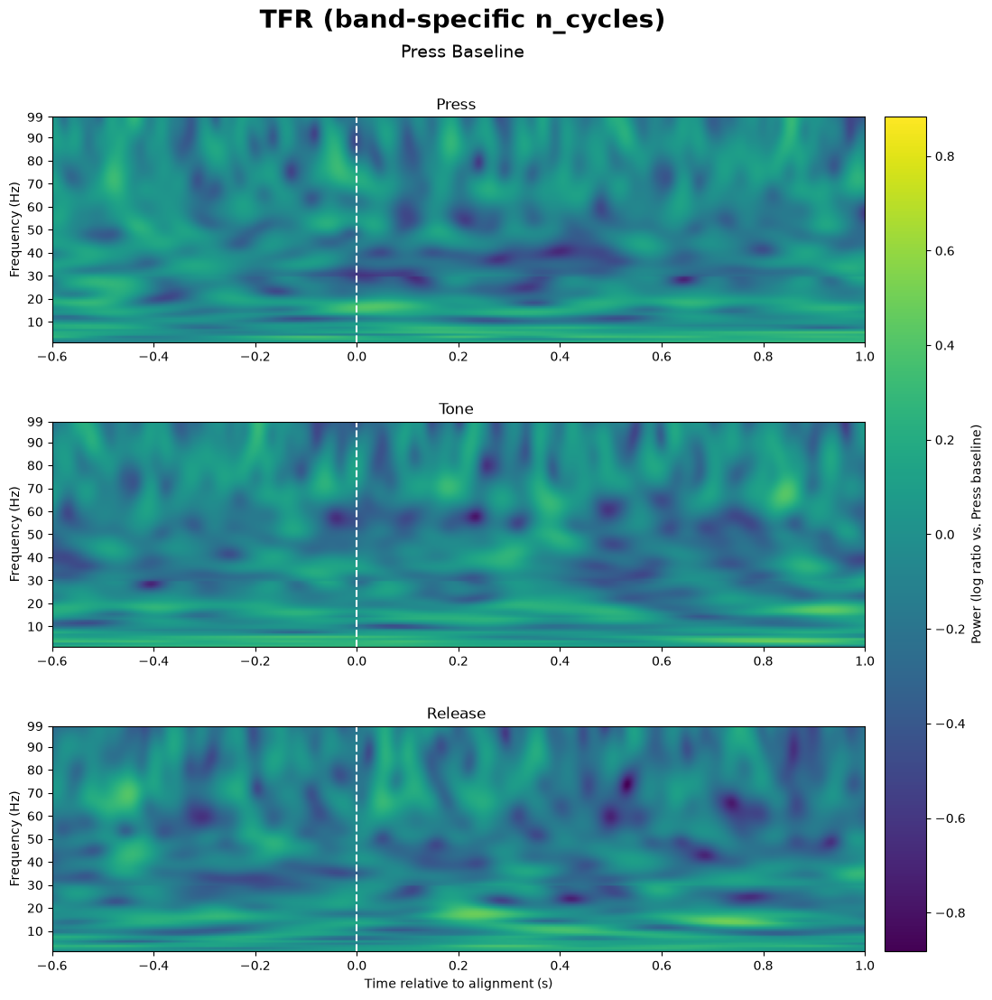

In [60]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True, sharey=True, gridspec_kw={'hspace': 0.35})

vmax = np.max(np.abs(np.concatenate([results_press_v2['Press'].ravel(), results_press_v2['Tone'].ravel(), results_press_v2['Release'].ravel()])))
# <-- CHECK: results_press_v2 (all three)

for ax, name in zip(axes, ['Press', 'Tone', 'Release']):
    im = ax.imshow(results_press_v2[name], aspect='auto', origin='lower',   # <-- CHECK: results_press_v2
                    extent=[times_v2[0], times_v2[-1], freqs_v2[0], freqs_v2[-1]],
                    cmap='viridis', vmin=-vmax, vmax=vmax)
    ax.axvline(0, color='white', linestyle='--', linewidth=1.5)
    ax.set_ylabel('Frequency (Hz)')
    ax.set_title(f'{name} ')
    ax.tick_params(axis='x', labelbottom=True)
    ax.set_yticks([10, 20, 30, 40, 50, 60, 70, 80, 90, 99])
    ax.set_ylim(1, 99)

axes[-1].set_xlabel('Time relative to alignment (s)')
fig.suptitle('TFR (band-specific n_cycles)', fontsize=20, fontweight='bold', x=0.45, y=0.98)
fig.text(0.45, 0.935, 'Press Baseline', ha='center', fontsize=14)
cbar = fig.colorbar(im, ax=axes, pad=0.02)
cbar.set_label('Power (log ratio vs. Press baseline)')
plt.tight_layout()
plt.show()

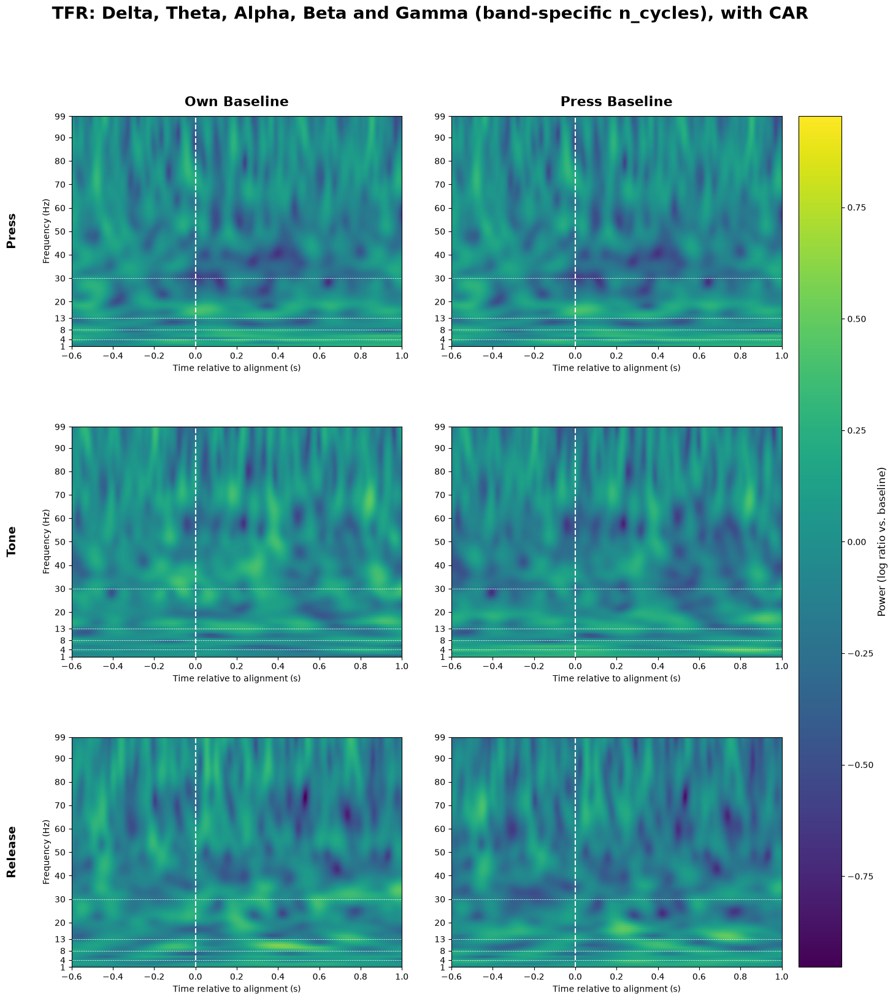

In [61]:
fig, axes = plt.subplots(3, 2, figsize=(18, 18), sharex=True, sharey=True, gridspec_kw={'hspace': 0.35, 'wspace': 0.15})

vmax = np.max(np.abs(np.concatenate([
    results_own_v2['Press'].ravel(), results_own_v2['Tone'].ravel(), results_own_v2['Release'].ravel(),
    results_press_v2['Press'].ravel(), results_press_v2['Tone'].ravel(), results_press_v2['Release'].ravel()
])))

row_names = ['Press', 'Tone', 'Release']

for row, name in enumerate(row_names):

    im = axes[row, 0].imshow(results_own_v2[name], aspect='auto', origin='lower',
                              extent=[times_v2[0], times_v2[-1], freqs_v2[0], freqs_v2[-1]],
                              cmap='viridis', vmin=-vmax, vmax=vmax)
    axes[row, 0].axvline(0, color='white', linestyle='--', linewidth=1.5)
    axes[row, 0].axhline(4, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].axhline(8, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].axhline(13, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].axhline(30, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].set_ylabel('Frequency (Hz)')
    axes[row, 0].text(-0.18, 0.5, name, transform=axes[row, 0].transAxes, rotation=90, va='center', ha='center', fontsize=14, fontweight='bold')
    axes[row, 0].set_yticks([1, 4, 8, 13, 20, 30, 40, 50, 60, 70, 80, 90, 99])
    axes[row, 0].set_ylim(1, 99)
    axes[row, 0].set_xlabel('Time relative to alignment (s)')
    axes[row, 0].tick_params(axis='x', which='both', labelbottom=True)

    axes[row, 1].imshow(results_press_v2[name], aspect='auto', origin='lower',
                         extent=[times_v2[0], times_v2[-1], freqs_v2[0], freqs_v2[-1]],
                         cmap='viridis', vmin=-vmax, vmax=vmax)
    axes[row, 1].axvline(0, color='white', linestyle='--', linewidth=1.5)
    axes[row, 1].axhline(4, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].axhline(8, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].axhline(13, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].axhline(30, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].set_yticks([1, 4, 8, 13, 20, 30, 40, 50, 60, 70, 80, 90, 99])
    axes[row, 1].set_ylim(1, 99)
    axes[row, 1].set_xlabel('Time relative to alignment (s)')
    axes[row, 1].tick_params(axis='x', which='both', labelbottom=True)

    axes[row, 0].tick_params(axis='y', which='both', labelleft=True)
    axes[row, 1].tick_params(axis='y', which='both', labelleft=True)

axes[0, 0].set_title('Own Baseline', fontsize=16, fontweight='bold', pad=12)
axes[0, 1].set_title('Press Baseline', fontsize=16, fontweight='bold', pad=12)

fig.suptitle('TFR: Delta, Theta, Alpha, Beta and Gamma (band-specific n_cycles), with CAR', fontsize=20, fontweight='bold', x=0.45, y=0.98)

cbar = fig.colorbar(im, ax=axes, pad=0.02)
cbar.set_label('Power (log ratio vs. baseline)', fontsize=12)
#plt.savefig(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260513_r0000136_wt_1729\amir_data\Time_Frequency_Analysis\with_CAR\n_cycles (customized)\Morlet_wavelet_with_CAR.png", dpi=300, bbox_inches="tight")

plt.show()

In [62]:
%matplotlib inline 
#Jupyter magic command so matplotlib plots render inline in the notebook instead of opening separate windows

import spikeinterface.full as si
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

spikeglx_folder = Path(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\0_raw\20260522_r0000136_wt_1750\ephys\26_05_22_136_1_neuropixels_g0\26_05_22_136_1_neuropixels_g0_imec0")

stream_names, stream_ids = si.get_neo_streams('spikeglx', spikeglx_folder)
#SpikeInterface reads SpikeGLX files through the neo library. 
#This function scans the folder and lists which streams (data channels of the acquisition system) exist.
stream_names

raw_rec = si.read_spikeglx(spikeglx_folder, stream_name='imec0.ap')
raw_rec


SpikeGLXRecordingExtractor: 384 channels - 30.0kHz - 1 segments - 89,672,760 samples 
                            2,989.09s (49.82 minutes) - int16 dtype - 64.14 GiB

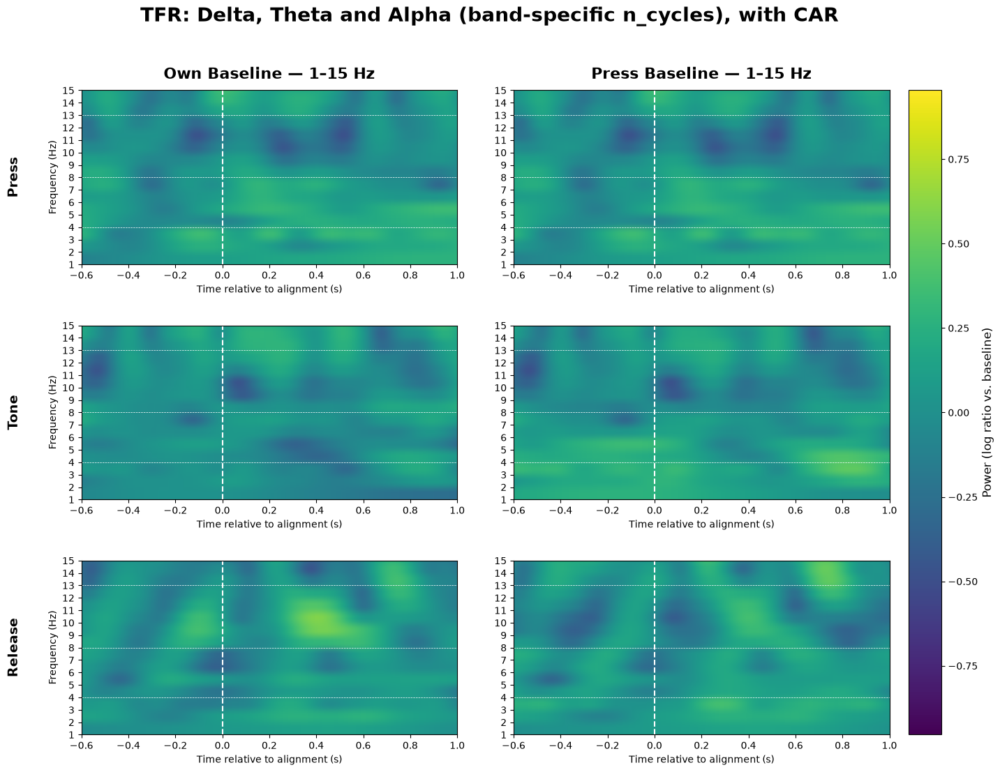

In [63]:
vmax = np.max(np.abs(np.concatenate([
    results_own_v2['Press'].ravel(), results_own_v2['Tone'].ravel(), results_own_v2['Release'].ravel(),
    results_press_v2['Press'].ravel(), results_press_v2['Tone'].ravel(), results_press_v2['Release'].ravel()
])))

fig, axes = plt.subplots(3, 2, figsize=(18, 12), sharex=True, sharey=True, gridspec_kw={'hspace': 0.35, 'wspace': 0.15})

row_names = ['Press', 'Tone', 'Release']

for row, name in enumerate(row_names):

    im = axes[row, 0].imshow(results_own_v2[name], aspect='auto', origin='lower',
                              extent=[times_v2[0], times_v2[-1], freqs_v2[0], freqs_v2[-1]],
                              cmap='viridis', vmin=-vmax, vmax=vmax)

    axes[row, 0].axvline(0, color='white', linestyle='--', linewidth=1.5)
    axes[row, 0].axhline(4, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].axhline(8, color='white', linestyle='--', linewidth=0.5)
    axes[row, 0].axhline(13, color='white', linestyle='--', linewidth=0.5)

    axes[row, 0].set_ylabel('Frequency (Hz)')
    axes[row, 0].text(-0.18, 0.5, name, transform=axes[row, 0].transAxes, rotation=90, va='center', ha='center', fontsize=14, fontweight='bold')
    axes[row, 0].set_yticks([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15])
    axes[row, 0].set_ylim(1, 15)
    axes[row, 0].set_xlabel('Time relative to alignment (s)')
    axes[row, 0].tick_params(axis='x', which='both', labelbottom=True)

    axes[row, 1].imshow(results_press_v2[name], aspect='auto', origin='lower',
                         extent=[times_v2[0], times_v2[-1], freqs_v2[0], freqs_v2[-1]],
                         cmap='viridis', vmin=-vmax, vmax=vmax)

    axes[row, 1].axvline(0, color='white', linestyle='--', linewidth=1.5)
    axes[row, 1].axhline(4, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].axhline(8, color='white', linestyle='--', linewidth=0.5)
    axes[row, 1].axhline(13, color='white', linestyle='--', linewidth=0.5)

    axes[row, 1].set_yticks([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15])
    axes[row, 1].set_ylim(1, 15)
    axes[row, 1].set_xlabel('Time relative to alignment (s)')
    axes[row, 1].tick_params(axis='x', which='both', labelbottom=True)

    axes[row, 0].tick_params(axis='y', which='both', labelleft=True)
    axes[row, 1].tick_params(axis='y', which='both', labelleft=True)

axes[0, 0].set_title('Own Baseline — 1–15 Hz', fontsize=16, fontweight='bold', pad=12)
axes[0, 1].set_title('Press Baseline — 1–15 Hz', fontsize=16, fontweight='bold', pad=12)

fig.suptitle('TFR: Delta, Theta and Alpha (band-specific n_cycles), with CAR', fontsize=20, fontweight='bold', x=0.45, y=0.98)

cbar = fig.colorbar(im, ax=axes, pad=0.02)
cbar.set_label('Power (log ratio vs. baseline)', fontsize=12)
#plt.savefig(session_dir + r"\amir_data\Time_Frequency_Analysis\with_CAR\n_cycles (customized)\Morlet_wavelet_zoom_with_CAR.png", dpi=300, bbox_inches="tight")

plt.show()

In [65]:
%matplotlib inline 
#Jupyter magic command so matplotlib plots render inline in the notebook instead of opening separate windows

import spikeinterface.full as si
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

spikeglx_folder = Path(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\0_raw\20260522_r0000136_wt_1750\ephys\26_05_22_136_1_neuropixels_g0\26_05_22_136_1_neuropixels_g0_imec0")

stream_names, stream_ids = si.get_neo_streams('spikeglx', spikeglx_folder)
#SpikeInterface reads SpikeGLX files through the neo library. 
#This function scans the folder and lists which streams (data channels of the acquisition system) exist.
stream_names

raw_rec = si.read_spikeglx(spikeglx_folder, stream_name='imec0.ap')
raw_rec


SpikeGLXRecordingExtractor: 384 channels - 30.0kHz - 1 segments - 89,672,760 samples 
                            2,989.09s (49.82 minutes) - int16 dtype - 64.14 GiB

In [1]:
selected_df = highlighted.reset_index(drop=True)
all_results_v2 = {}  

for _, row in selected_df.iterrows():
    channel_id = row['channel_id']

    raw_power_ch = {}   

    for name, column in {'Press': 'press_np_s', 'Tone': 'tone_np_s', 'Release': 'release_np_s'}.items():
        align_idx = (l_C[column].dropna().values * fs).astype(int)
        arr_list = []

        for idx in align_idx:
            start, end = idx - n_pre_v2, idx + n_post_v2
            trace = ds_data.get_traces(start_frame=start, end_frame=end, channel_ids=[channel_id], return_in_uV=True)
            if trace.shape[0] == n_total_v2:
                arr_list.append(trace[:, 0])

        arr_3 = np.array(arr_list)[:, np.newaxis, :]
        info = mne.create_info(ch_names=[channel_id], sfreq=fs, ch_types='seeg')
        epochs = mne.EpochsArray(arr_3, info, tmin=tmin_v2, verbose=False)

        band_power_objs = []
        for band in band_settings:
            power = epochs.compute_tfr(method='morlet', freqs=band['freqs'], n_cycles=band['n_cycles'],
                                        use_fft=True, return_itc=False, average=True,
                                        decim=1, n_jobs=1, verbose=False)
            band_power_objs.append(power)

        raw_power_ch[name] = band_power_objs

    # apply Press baseline per band, crop, stitch — same logic as your single-channel Cell 4
    baseline_win = (-0.5, -0.2)
    crop_win = (-0.6, 1)

    ch_results = {name: [] for name in ['Press', 'Tone', 'Release']}

    for b_idx, band in enumerate(band_settings):
        press_power_band = raw_power_ch['Press'][b_idx]
        press_times_band = press_power_band.times
        b_mask = (press_times_band >= baseline_win[0]) & (press_times_band <= baseline_win[1])
        baseline_power_band = press_power_band.data[:, :, b_mask].mean(axis=-1, keepdims=True)

        crop_mask = (press_times_band >= crop_win[0]) & (press_times_band <= crop_win[1])

        for name in ['Press', 'Tone', 'Release']:
            power_band = raw_power_ch[name][b_idx]
            band_result = np.log10(power_band.data / baseline_power_band)[0]
            ch_results[name].append(band_result[:, crop_mask])

    for name in ch_results:
        ch_results[name] = np.concatenate(ch_results[name], axis=0)

    all_results_v2[channel_id] = ch_results

    print(f"Done: {channel_id}")

# frequency and time axes, same for every channel/condition since bands/crop are fixed
freqs_multi_v2 = np.concatenate([band['freqs'] for band in band_settings])
times_multi_v2 = press_power_band.times[crop_mask]

NameError: name 'highlighted' is not defined

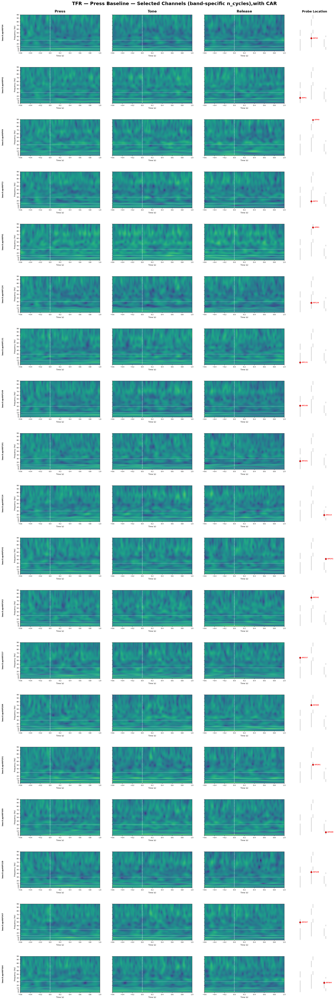

In [ ]:
n_channels = len(selected_df)
conditions = ['Press', 'Tone', 'Release']
frequency_ticks = [1, 4, 8, 13, 20, 30, 40, 50, 60, 70, 80, 90, 99]
oscillation_boundaries = [4, 8, 13, 30]

all_values = np.concatenate([all_results_v2[ch][cond].ravel()[np.isfinite(all_results_v2[ch][cond].ravel())] for ch in all_results_v2 for cond in conditions])
vmax = np.max(np.abs(all_values))

probe = ds_data.get_probe()
probe_df = probe.to_dataframe().copy()
channel_ids = ds_data.get_channel_ids()
probe_df['channel_id'] = [channel_ids[i] for i in probe.device_channel_indices]

fig, axes = plt.subplots(n_channels, 4, figsize=(22, 3.2 * n_channels), gridspec_kw={'width_ratios': [1, 1, 1, 0.45], 'wspace': 0.18, 'hspace': 0.45})

if n_channels == 1: axes = axes[np.newaxis, :]

for row, (_, channel_row) in enumerate(selected_df.iterrows()):
    channel_id = channel_row['channel_id']
    channel_x = channel_row['x']
    channel_y = channel_row['y']

    for col, condition in enumerate(conditions):
        ax = axes[row, col]
        im = ax.imshow(all_results_v2[channel_id][condition], aspect='auto', origin='lower',
                        extent=[times_multi_v2[0], times_multi_v2[-1], freqs_multi_v2[0], freqs_multi_v2[-1]],
                        cmap='viridis', vmin=-vmax, vmax=vmax, interpolation='bilinear')
        ax.axvline(0, color='white', linestyle='--', linewidth=1.2)
        [ax.axhline(f, color='white', linestyle='--', linewidth=0.6) for f in oscillation_boundaries]
        ax.set_ylim(1, 99)
        ax.set_yticks(frequency_ticks)
        ax.set_xlim(times_multi_v2[0], times_multi_v2[-1])
        ax.grid(False)
        ax.tick_params(axis='both', which='both', length=3, labelsize=7)
        ax.set_xlabel('Time (s)', fontsize=8)

        if col == 0:
            ax.set_ylabel('Frequency (Hz)', fontsize=8)
            ax.text(-0.22, 0.5, channel_id, transform=ax.transAxes, rotation=90, va='center', ha='center', fontsize=8, fontweight='bold')
        else:
            ax.set_ylabel('')
            ax.tick_params(axis='y', labelleft=False)

    ax_probe = axes[row, 3]
    ax_probe.scatter(probe_df['x'], probe_df['y'], s=7, color='lightgray', edgecolors='none')
    ax_probe.scatter(channel_x, channel_y, s=50, color='red', edgecolors='black', linewidths=0.5, zorder=10)
    ax_probe.text(channel_x + 30, channel_y, channel_id.replace('imec0.ap#AP', 'AP'), color='red', fontsize=7, fontweight='bold', va='center', zorder=11)
    ax_probe.set_xlim(probe_df['x'].min() - 70, probe_df['x'].max() + 130)
    ax_probe.set_ylim(probe_df['y'].max() + 40, probe_df['y'].min() - 40)
    ax_probe.set_xticks([])
    ax_probe.set_yticks([])
    ax_probe.grid(False)
    ax_probe.set_xlabel('')
    ax_probe.set_ylabel('')
    [spine.set_visible(False) for spine in ax_probe.spines.values()]

axes[0, 0].set_title('Press', fontsize=15, fontweight='bold', pad=10)
axes[0, 1].set_title('Tone', fontsize=15, fontweight='bold', pad=10)
axes[0, 2].set_title('Release', fontsize=15, fontweight='bold', pad=10)
axes[0, 3].set_title('Probe Location', fontsize=13, fontweight='bold', pad=10)

fig.suptitle('TFR — Press Baseline — Selected Channels (band-specific n_cycles),with CAR', fontsize=20, fontweight='bold', y=0.998)

plt.subplots_adjust(left=0.08, right=0.93, top=0.985, bottom=0.025, wspace=0.15, hspace=0.45)
plt.savefig(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260513_r0000136_wt_1729\amir_data\Time_Frequency_Analysis\with_CAR\n_cycles (customized)\Morlet_wavelet_across channeels_with_CAR.png", dpi=300, bbox_inches="tight")

plt.show()

Early AND Short trials: 21
Early AND Long trials: 62
Early + Short:
  Press: 21 trials used, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
  Release: 21 trials used, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)


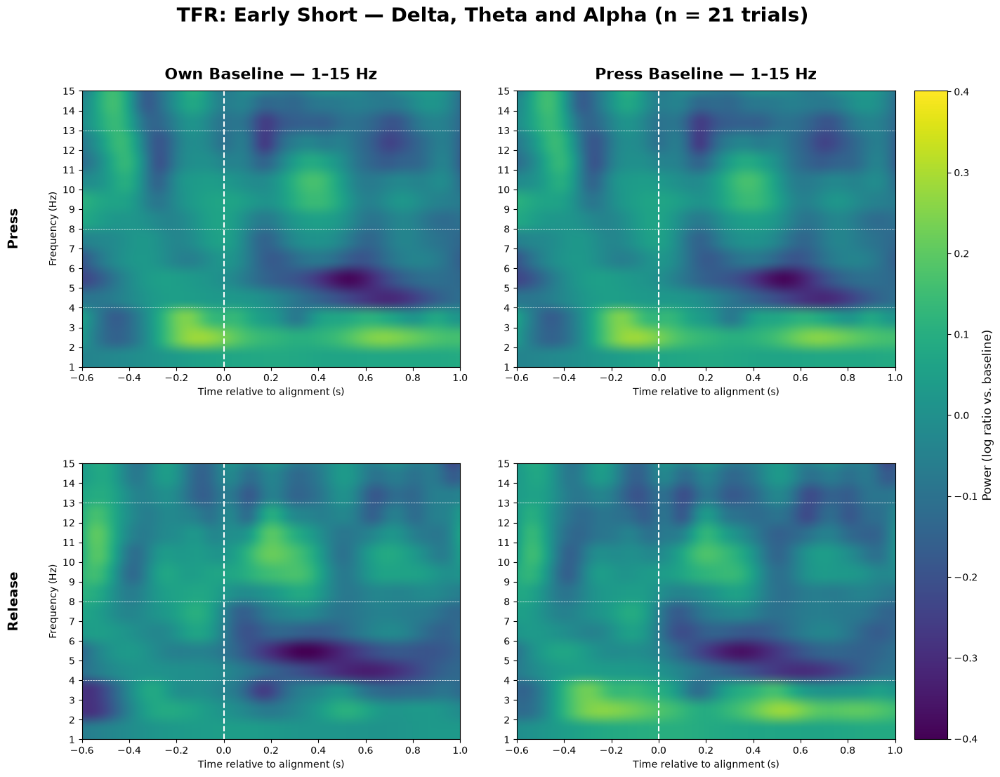

Early + Long:
  Press: 62 trials used, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
  Release: 62 trials used, [(1, 3, 6000), (1, 4, 6000), (1, 5, 6000), (1, 17, 6000), (1, 70, 6000)]
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)


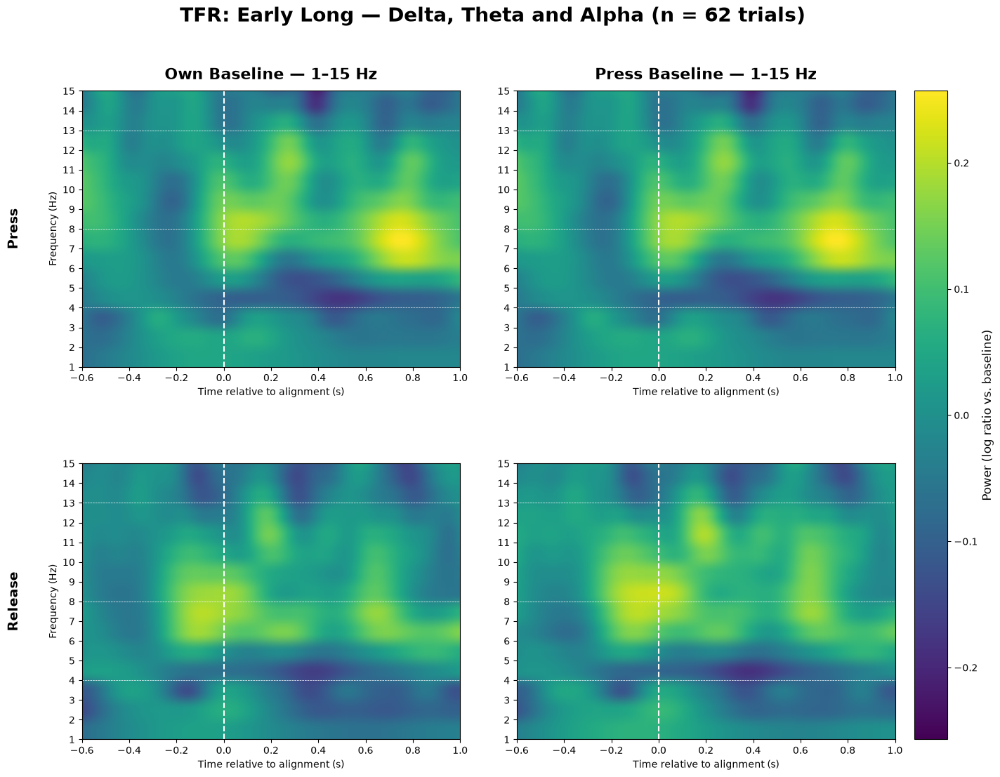

In [75]:
import numpy as np
import matplotlib.pyplot as plt
import mne

# ================================================
# Fix tone_np_s for early trials (tone never happened / not meaningful)
# ================================================
beh["tone_np_s"] = (beh["tone"] - beh["press"]) + beh["press_np_s"]
beh.loc[beh["early"] == 1, "tone_np_s"] = np.nan

# ================================================
# Build the two trial subsets
# ================================================
early_short = beh[(beh["early"] == 1) & (beh["short"] == 1)]
early_long  = beh[(beh["early"] == 1) & (beh["long"] == 1)]

print(f"Early AND Short trials: {len(early_short)}")
print(f"Early AND Long trials: {len(early_long)}")

# ================================================
# Shared TFR settings (fs and ds_data reused as already defined in your kernel)
# ================================================
channel_id = 'imec0.ap#AP0'

tmin_v2 = -3
tmax_v2 = 3
n_pre_v2 = round(fs * abs(tmin_v2))
n_post_v2 = round(fs * tmax_v2)
n_total_v2 = n_pre_v2 + n_post_v2

band_settings = [
    {'freqs': np.arange(1, 4, 1),    'n_cycles': 2},   # delta
    {'freqs': np.arange(4, 8, 1),    'n_cycles': 5},   # theta
    {'freqs': np.arange(8, 13, 1),   'n_cycles': 6},   # alpha
    {'freqs': np.arange(13, 30, 1),  'n_cycles': 7},   # beta
    {'freqs': np.arange(30, 100, 1), 'n_cycles': 10},  # gamma
]

baseline_win = (-0.5, -0.2)
crop_win = (-0.6, 1)

# early trials only have Press and Release — no real Tone event
event_columns = {'Press': 'press_np_s', 'Release': 'release_np_s'}

# ================================================
# Compute raw (unbaselined) per-band TFR power for a trial subset
# ================================================
def compute_raw_tfr(trial_subset):
    raw_power = {}

    for name, column in event_columns.items():
        align_idx = (trial_subset[column].dropna().values * fs).astype(int)

        arr_list = []
        for idx in align_idx:
            start, end = idx - n_pre_v2, idx + n_post_v2
            trace = ds_data.get_traces(start_frame=start, end_frame=end, channel_ids=[channel_id], return_in_uV=True)
            if trace.shape[0] == n_total_v2:
                arr_list.append(trace[:, 0])

        if len(arr_list) == 0:
            print(f"  No valid trials for {name} — skipping.")
            raw_power[name] = None
            continue

        arr_3 = np.array(arr_list)[:, np.newaxis, :]
        info = mne.create_info(ch_names=[channel_id], sfreq=fs, ch_types='seeg')
        epochs = mne.EpochsArray(arr_3, info, tmin=tmin_v2, verbose=False)

        band_power_objs = []
        for band in band_settings:
            power = epochs.compute_tfr(method='morlet', freqs=band['freqs'], n_cycles=band['n_cycles'],
                                        use_fft=True, return_itc=False, average=True,
                                        decim=1, n_jobs=1, verbose=False)
            band_power_objs.append(power)

        raw_power[name] = band_power_objs
        print(f"  {name}: {len(arr_list)} trials used, {[p.data.shape for p in band_power_objs]}")

    return raw_power

# ================================================
# Apply own-baseline and Press-baseline correction, stitched across bands
# ================================================
def apply_baselines(raw_power):
    results_own = {name: [] for name in event_columns}
    results_press = {name: [] for name in event_columns}

    press_power_list = raw_power.get('Press')
    if press_power_list is None:
        print("  No Press data available — cannot compute Press-baseline.")
        return None, None, None, None

    for b_idx, band in enumerate(band_settings):

        for name in event_columns:
            power_band = raw_power.get(name)
            if power_band is None:
                continue
            p_copy = power_band[b_idx].copy()
            p_copy.apply_baseline(baseline=baseline_win, mode='logratio')
            p_copy.crop(tmin=crop_win[0], tmax=crop_win[1])
            results_own[name].append(p_copy.data[0])

        press_power_band = press_power_list[b_idx]
        press_times_band = press_power_band.times
        b_mask = (press_times_band >= baseline_win[0]) & (press_times_band <= baseline_win[1])
        baseline_power_band = press_power_band.data[:, :, b_mask].mean(axis=-1, keepdims=True)

        crop_mask = (press_times_band >= crop_win[0]) & (press_times_band <= crop_win[1])

        for name in event_columns:
            power_band = raw_power.get(name)
            if power_band is None:
                continue
            band_result = np.log10(power_band[b_idx].data / baseline_power_band)[0]
            results_press[name].append(band_result[:, crop_mask])

    for name in event_columns:
        if len(results_own[name]) > 0:
            results_own[name] = np.concatenate(results_own[name], axis=0)
        if len(results_press[name]) > 0:
            results_press[name] = np.concatenate(results_press[name], axis=0)

    freqs = np.concatenate([band['freqs'] for band in band_settings])
    times = press_power_band.times[crop_mask]

    return results_own, results_press, freqs, times

# ================================================
# Plot: zoomed 1–15 Hz version, 2 rows (Press, Release) x 2 cols (Own vs Press baseline)
# ================================================
def plot_early_tfr_zoom(results_own, results_press, freqs, times, title_suffix, n_trials):
    row_names = ['Press', 'Release']

    vmax = np.max(np.abs(np.concatenate([
        results_own['Press'].ravel(), results_own['Release'].ravel(),
        results_press['Press'].ravel(), results_press['Release'].ravel()
    ])))

    fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharex=True, sharey=True,
                              gridspec_kw={'hspace': 0.35, 'wspace': 0.15})

    for row, name in enumerate(row_names):

        im = axes[row, 0].imshow(results_own[name], aspect='auto', origin='lower',
                                  extent=[times[0], times[-1], freqs[0], freqs[-1]],
                                  cmap='viridis', vmin=-vmax, vmax=vmax)

        axes[row, 0].axvline(0, color='white', linestyle='--', linewidth=1.5)
        axes[row, 0].axhline(4, color='white', linestyle='--', linewidth=0.5)
        axes[row, 0].axhline(8, color='white', linestyle='--', linewidth=0.5)
        axes[row, 0].axhline(13, color='white', linestyle='--', linewidth=0.5)

        axes[row, 0].set_ylabel('Frequency (Hz)')
        axes[row, 0].text(-0.18, 0.5, name, transform=axes[row, 0].transAxes, rotation=90,
                           va='center', ha='center', fontsize=14, fontweight='bold')
        axes[row, 0].set_yticks([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15])
        axes[row, 0].set_ylim(1, 15)
        axes[row, 0].set_xlabel('Time relative to alignment (s)')
        axes[row, 0].tick_params(axis='x', which='both', labelbottom=True)

        axes[row, 1].imshow(results_press[name], aspect='auto', origin='lower',
                             extent=[times[0], times[-1], freqs[0], freqs[-1]],
                             cmap='viridis', vmin=-vmax, vmax=vmax)

        axes[row, 1].axvline(0, color='white', linestyle='--', linewidth=1.5)
        axes[row, 1].axhline(4, color='white', linestyle='--', linewidth=0.5)
        axes[row, 1].axhline(8, color='white', linestyle='--', linewidth=0.5)
        axes[row, 1].axhline(13, color='white', linestyle='--', linewidth=0.5)

        axes[row, 1].set_yticks([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15])
        axes[row, 1].set_ylim(1, 15)
        axes[row, 1].set_xlabel('Time relative to alignment (s)')
        axes[row, 1].tick_params(axis='x', which='both', labelbottom=True)

        axes[row, 0].tick_params(axis='y', which='both', labelleft=True)
        axes[row, 1].tick_params(axis='y', which='both', labelleft=True)

    axes[0, 0].set_title('Own Baseline — 1–15 Hz', fontsize=16, fontweight='bold', pad=12)
    axes[0, 1].set_title('Press Baseline — 1–15 Hz', fontsize=16, fontweight='bold', pad=12)

    fig.suptitle(f'TFR: Early {title_suffix} — Delta, Theta and Alpha (n = {n_trials} trials)',
                  fontsize=20, fontweight='bold', x=0.45, y=0.98)

    cbar = fig.colorbar(im, ax=axes, pad=0.02)
    cbar.set_label('Power (log ratio vs. baseline)', fontsize=12)

    plt.show()

# ================================================
# Run for Early + Short
# ================================================
print("Early + Short:")
raw_power_short = compute_raw_tfr(early_short)
results_own_short, results_press_short, freqs_v2, times_v2 = apply_baselines(raw_power_short)
if results_own_short is not None:
    plot_early_tfr_zoom(results_own_short, results_press_short, freqs_v2, times_v2, "Short", len(early_short))

# ================================================
# Run for Early + Long
# ================================================
print("Early + Long:")
raw_power_long = compute_raw_tfr(early_long)
results_own_long, results_press_long, freqs_v2, times_v2 = apply_baselines(raw_power_long)
if results_own_long is not None:
    plot_early_tfr_zoom(results_own_long, results_press_long, freqs_v2, times_v2, "Long", len(early_long))